# Module 5: Coordinated Visual Analysis
**220 points · one 3–4-minute VoiceThread · due Sunday of Module 5 at 11:55 p.m. Eastern Time**

**Notebook:** `M05_Coordinated_Visual_Analysis.ipynb` · **Release:** `2026.11.15.5`

Module 4 emphasized building and explaining individual views. Module 5 extends that work by coordinating three views to compare alternatives and support a decision, with additional cost-based evidence.

This notebook regenerates the same workshop data and all five earlier base views from your student integer. Choose two base views, improve them, and create the new cost–demand visualization. Complete the Markdown explanation directly beneath each of your three final visualizations.

Your three assessed visualizations are:
1. An improved version of one selected base view.
2. An improved version of a different selected base view.
3. One new visualization using additional variables or derived measures, with an initial draft and a revised version.

The code recreates the base views here. You do not need to transfer old chart code, images, or a Module 4 runtime folder but you can _update & resuse_ your Module 4 work when useful.

**All students** complete the workshop section. **Graduate students, or undergraduates who want bonus points** then apply the same process to independently selected data. DSC 363/BUS 363 normally presents the workshop work; DSC 563 presents the external-data work. Submit one presentation.


## All students
For the workshop coordinator, investigate: **Which workshop topic and delivery format should receive priority for one additional pilot session, considering recorded demand, capacity utilization, and operating cost?** Recommend one option, compare a plausible alternative, and explain a limitation.

The five regenerated base views cover group comparisons, distributions, relationships, time, and small multiples. Choose the two that best support this decision. Make at least one purposeful improvement to each selected view, informed by instructor feedback, a course resource, or an external source. The new cost–demand view also needs a documented improvement from its first draft.

Colab students run the code in order. Tableau students run through the data-pack download, then construct the same five base forms in Tableau, choose two to improve, and build the new visualization using the calculation notes. You may use either tool.


### 1. Set your student integer and course level
Save a personal copy in Drive. Enter your assigned integer from 1–200; zero is for practice. Course-level and data settings belong in code. Explanations, feedback, sources, and interpretation belong in the Markdown cells beneath the visualizations.


In [1]:
# Load the libraries used throughout this notebook.
from pathlib import Path
import hashlib
import io
import json
import math
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator
from IPython.display import display


In [2]:
# Step 1: Set Course Level and Student Integer (0 for practice, 1-200 for personal data)
COURSE_LEVEL = '563'  # Choose '363' (Undergrad) or '563' (Graduate)
STUDENT_INTEGER = 23  # Your assigned unique identifier
UNDERGRAD_USE_OWN_DATA = False  # Set to True if completing the undergraduate bonus track

# Step 2: Define Workshop Analysis Parameters
WORKSHOP_AUDIENCE = 'Workshop coordinator'  # Primary stakeholder
WORKSHOP_QUESTION = 'Which topic and delivery format should receive priority for one additional pilot session?'

# System Configuration: Directories, plotting styles, and safety checks
MODULE = 5
NOTEBOOK_RELEASE = '2026.11.15.5'
if COURSE_LEVEL not in {'363', '563'}:
    raise ValueError("Enter COURSE_LEVEL as '363' or '563'.")
if isinstance(STUDENT_INTEGER, bool) or not isinstance(STUDENT_INTEGER, int) or not 0 <= STUDENT_INTEGER <= 200:
    raise ValueError('Use your assigned whole-number integer from 1–200, or 0 for practice.')

COMPLETE_EXTERNAL_PHASE = COURSE_LEVEL == '563' or UNDERGRAD_USE_OWN_DATA
WORK_ROOT = Path(f'm{MODULE:02d}_integer_{STUDENT_INTEGER}')
COURSE_DIR = WORK_ROOT / 'all_students_workshop'
COURSE_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({'figure.dpi': 120, 'font.size': 12,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'savefig.bbox': 'tight'})

print(f'Module {MODULE} | release {NOTEBOOK_RELEASE} | course {COURSE_LEVEL} | integer {STUDENT_INTEGER}')
if STUDENT_INTEGER == 0:
    print('PRACTICE: enter your assigned integer before preparing assessed work.')
print('Complete All students first. External-data section selected:', COMPLETE_EXTERNAL_PHASE)

Module 5 | release 2026.11.15.5 | course 563 | integer 23
Complete All students first. External-data section selected: True


### 2. Generate the same workshop records
Run the generator unchanged. The same integer recreates the same source records, including missing attendance reports.


In [3]:
"""Frozen workshop-session generator embedded in each student notebook."""
import hashlib
import numpy as np
import pandas as pd

DATASET_VERSION = 'WORKSHOP-SESSIONS-1'

def make_workshop_data(integer):
    # A fresh PCG64 generator makes repeated runs with this integer repeat the records.
    rng = np.random.Generator(np.random.PCG64(integer))
    neighborhoods = ['North', 'East', 'South', 'West', 'Central', 'Riverside']
    topics = ['Digital skills', 'Career skills', 'Creative practice', 'Personal finance']
    formats = ['In person', 'Online']
    schedules = ['Weekday daytime', 'Weekday evening', 'Weekend']
    # Neighborhood and topic differences create comparisons without implying real findings.
    area_effect = dict(zip(neighborhoods, rng.normal(0, .08, len(neighborhoods))))
    topic_effect = dict(zip(topics, rng.normal(0, .09, len(topics))))
    rows = []
    for month in range(1, 25):
        cycle = .08 * np.sin(2 * np.pi * (month - 1) / 12)
        for area in neighborhoods:
            for topic_index, topic in enumerate(topics):
                for delivery in formats:
                    # Between one and three sessions per combination varies group sizes.
                    for repeat in range(int(rng.integers(1, 4))):
                        schedule = str(rng.choice(schedules, p=[.28, .47, .25]))
                        duration = float(rng.choice([1., 1.5, 2., 2.5, 3.]))
                        capacity = int(rng.integers(18, 81) if delivery == 'In person' else rng.integers(45, 181))
                        demand = (.74 + area_effect[area] + topic_effect[topic] + cycle
                                  + .004 * (month - 12) + (.09 if schedule == 'Weekday evening' else -.02)
                                  + (.08 if delivery == 'Online' else 0) + rng.normal(0, .18))
                        requests = max(0, int(round(capacity * demand)))
                        registrations = min(capacity, requests)
                        waitlist = max(0, requests - capacity)
                        # Registrations are confirmed places; this exercise assumes no walk-ins.
                        show_probability = float(np.clip(.85 + (.05 if delivery == 'In person' else -.07)
                                                        - .025 * (duration - 1) + rng.normal(0, .05), .45, .99))
                        attendance = int(rng.binomial(registrations, show_probability))
                        cost = round(max(20., 90 + 65 * duration + (.8 if delivery == 'In person' else .25) * capacity
                                         + 16 * topic_index + rng.normal(0, 23)), 2)
                        response_probability = float(np.clip(.40 + (.12 if delivery == 'In person' else -.12)
                                                             + rng.normal(0, .06), .05, .85))
                        responses = int(rng.binomial(attendance, response_probability))
                        # Ratings summarize responders only; they do not measure all attendees.
                        satisfaction = (round(float(np.clip(3.8 + .15 * topic_index + .07 * (duration - 2)
                                                           + rng.normal(0, .35), 1, 5)), 2)
                                        if responses else np.nan)
                        rows.append({'session_id': f'WS-{len(rows)+1:05d}', 'month': month,
                                     'neighborhood': area, 'topic': topic, 'delivery_format': delivery,
                                     'schedule': schedule, 'duration_hours': duration,
                                     'capacity_seats': capacity, 'registrations': registrations,
                                     'attendance_visits': float(attendance), 'waitlist_count': waitlist,
                                     'operating_cost_usd': cost, 'survey_response_count': float(responses),
                                     'mean_satisfaction': satisfaction})
    frame = pd.DataFrame(rows)
    # Missing reports are more common in East; missing attendance is never replaced by zero.
    missing = rng.random(len(frame)) < np.where(frame['neighborhood'].eq('East'), .08, .025)
    frame.loc[missing, ['attendance_visits', 'survey_response_count', 'mean_satisfaction']] = np.nan
    return frame

def validate_workshop_data(frame):
    # Check the session grain, categories, finite quantities, and operational constraints.
    assert frame.shape[1] == 14 and frame['session_id'].is_unique
    assert frame['month'].between(1, 24).all() and frame['month'].nunique() == 24
    assert frame['neighborhood'].nunique() == 6 and frame['topic'].nunique() == 4
    assert (frame['capacity_seats'] > 0).all() and (frame['operating_cost_usd'] > 0).all()
    assert frame['registrations'].between(0, frame['capacity_seats']).all()
    observed = frame.dropna(subset=['attendance_visits'])
    assert observed['attendance_visits'].between(0, observed['registrations']).all()
    assert observed['survey_response_count'].between(0, observed['attendance_visits']).all()
    assert (frame['waitlist_count'] >= 0).all()
    assert (frame.loc[frame['waitlist_count'].gt(0), 'registrations'] == frame.loc[frame['waitlist_count'].gt(0), 'capacity_seats']).all()
    assert frame['mean_satisfaction'].dropna().between(1, 5).all()
    assert frame.loc[frame['survey_response_count'].eq(0), 'mean_satisfaction'].isna().all()
    assert frame['attendance_visits'].isna().any()
    assert np.isfinite(frame.select_dtypes('number').to_numpy()[~frame.select_dtypes('number').isna().to_numpy()]).all()

def data_fingerprint(frame):
    # A canonical export preserves decimal precision; row order is part of this identity.
    canonical = frame.to_csv(index=False, na_rep='NA', float_format='%.8f', lineterminator='\n')
    return hashlib.sha256(canonical.encode('utf-8')).hexdigest()[:16]

def workshop_summary(frame, by='neighborhood'):
    # Calculate each ratio on the rows where its numerator and denominator are both known.
    result = frame.groupby(by, observed=True).agg(sessions=('session_id', 'size'),
        capacity_all=('capacity_seats', 'sum'), registrations=('registrations', 'sum'),
        waitlist_count=('waitlist_count', 'sum'), operating_cost_usd=('operating_cost_usd', 'sum'))
    observed = frame.dropna(subset=['attendance_visits']).copy()
    observed['session_utilization_pct'] = 100 * observed['attendance_visits'] / observed['capacity_seats']
    known = observed.groupby(by, observed=True).agg(observed_sessions=('session_id', 'size'),
        attendance_visits=('attendance_visits', 'sum'), capacity_observed=('capacity_seats', 'sum'),
        registrations_observed=('registrations', 'sum'), cost_observed=('operating_cost_usd', 'sum'),
        mean_session_utilization_pct=('session_utilization_pct', 'mean'))
    result = result.join(known)
    result['utilization_pct'] = 100 * result['attendance_visits'] / result['capacity_observed']
    result['attendance_rate_pct'] = 100 * result['attendance_visits'] / result['registrations_observed'].replace(0, np.nan)
    result['cost_per_visit_usd'] = result['cost_observed'] / result['attendance_visits'].replace(0, np.nan)
    result['zero_assumption_pct'] = 100 * result['attendance_visits'] / result['capacity_all']
    result['coverage_pct'] = 100 * result['observed_sessions'] / result['sessions']
    responses = observed.dropna(subset=['survey_response_count']).groupby(by, observed=True).agg(
        survey_response_count=('survey_response_count', 'sum'), survey_attendance=('attendance_visits', 'sum'))
    result = result.join(responses)
    result['response_rate_pct'] = 100 * result['survey_response_count'] / result['survey_attendance'].replace(0, np.nan)
    ratings = frame.dropna(subset=['mean_satisfaction', 'survey_response_count']).copy()
    ratings['rating_sum_approx'] = ratings['mean_satisfaction'] * ratings['survey_response_count']
    rating_totals = ratings.groupby(by, observed=True).agg(rating_sum_approx=('rating_sum_approx', 'sum'),
        rating_responses=('survey_response_count', 'sum'), equal_session_rating=('mean_satisfaction', 'mean'))
    result = result.join(rating_totals)
    result['response_weighted_rating'] = result['rating_sum_approx'] / result['rating_responses'].replace(0, np.nan)
    return result


### Inspect the generated data
One row represents one simulated workshop session. Inspect the dimensions, missing values, and fingerprint before interpreting the charts. Missing attendance is unknown and remains missing.


In [4]:
# Generate the workshop source without changing the established generator.
course_data = make_workshop_data(STUDENT_INTEGER)
validate_workshop_data(course_data)
course_fingerprint = data_fingerprint(course_data)
course_identity = {
    'section': 'All students', 'route': 'provided', 'student_integer': STUDENT_INTEGER,
    'notebook_release': NOTEBOOK_RELEASE, 'dataset_version': DATASET_VERSION,
    'shape': list(course_data.shape), 'fingerprint': course_fingerprint,
    'source': 'Simulated community-workshop sessions generated by this notebook',
    'row_meaning': 'One fictional workshop session'
}

# Display checks without deleting rows or replacing missing attendance.
display(pd.Series(course_identity, dtype=object).to_frame('Value'))
display(course_data.head())
display(course_data.isna().sum().rename('Missing values').to_frame())
print('Duplicate complete rows:', int(course_data.duplicated().sum()), '(reported, not deleted)')

# Retain the workshop source separately from the external source used later.
course_data.to_csv(COURSE_DIR / 'workshop_sessions.csv', index=False, na_rep='NA')
(COURSE_DIR / 'dataset_identity.json').write_text(json.dumps(course_identity, indent=2), encoding='utf-8')


,Value
section,All students
route,provided
student_integer,23
notebook_release,2026.11.15.5
dataset_version,WORKSHOP-SESSIONS-1
shape,"[2287, 14]"
fingerprint,1bebe6d2991b5682
source,Simulated community-workshop sessions generate...
row_meaning,One fictional workshop session


,session_id,month,neighborhood,topic,delivery_format,schedule,duration_hours,capacity_seats,registrations,attendance_visits,waitlist_count,operating_cost_usd,survey_response_count,mean_satisfaction
0,WS-00001,1,North,Digital skills,In person,Weekday evening,2.0,48,48,41.0,9,241.74,21.0,4.62
1,WS-00002,1,North,Digital skills,In person,Weekday daytime,1.0,35,26,20.0,0,185.06,7.0,4.19
2,WS-00003,1,North,Digital skills,In person,Weekend,2.5,20,20,18.0,6,258.68,10.0,3.41
3,WS-00004,1,North,Digital skills,Online,Weekday evening,1.5,62,55,34.0,0,183.21,9.0,4.42
4,WS-00005,1,North,Digital skills,Online,Weekday evening,2.0,90,85,70.0,0,233.48,21.0,3.37


,Missing values
session_id,0
month,0
neighborhood,0
topic,0
delivery_format,0
schedule,0
duration_hours,0
capacity_seats,0
registrations,0
attendance_visits,75


Duplicate complete rows: 0 (reported, not deleted)


364

### Workshop data dictionary
The supplied data are **simulated**. They support operational comparisons, not findings about real communities. Month numbers are fictional periods, not calendar dates. For online sessions, neighborhood means the service area.

| Field | Meaning |
|---|---|
| `session_id` | Unique workshop-session identifier |
| `month` | Numbered monthly period, 1–24 |
| `neighborhood` | One of six fictional service areas |
| `topic` | One of four workshop topics |
| `delivery_format` | In person or online |
| `schedule` | Weekday daytime, weekday evening, or weekend |
| `duration_hours` | Length of the session, in hours |
| `capacity_seats` | Available seat opportunities |
| `registrations` | Confirmed registrations, at most capacity; this exercise assumes no walk-ins |
| `attendance_visits` | Recorded seat visits; missing means unknown, not zero |
| `waitlist_count` | Recorded requests beyond confirmed places; not unique people across sessions |
| `operating_cost_usd` | Session operating cost in US dollars |
| `survey_response_count` | Number of attendees responding to the session survey |
| `mean_satisfaction` | Responders' mean rating on a 1–5 scale; missing if no recorded responses |

Attendance and waitlists may include repeat participants across sessions. They do not measure unique reach, program effectiveness, or equitable access. Do not infer causes from these descriptive records.


### Chart functions used throughout the notebook
Run this cell unchanged. It creates the five base forms and provides reusable settings for your selected improvements. Every saved chart receives a distinct filename, preserving earlier versions.


In [5]:
def save_report(fig, path, audience, question, source_label, fingerprint):
    fig.suptitle(f'{audience}: {question}', fontsize=13, wrap=True)
    fig.text(.01, .01, f'{source_label} | data {fingerprint}', fontsize=8, wrap=True)
    fig.tight_layout(rect=(0, .07, 1, .90))
    saved_path = path
    version = 2
    while saved_path.exists():
        saved_path = path.with_name(f'{path.stem}_v{version:02d}{path.suffix}')
        version += 1
    fig.savefig(saved_path)
    plt.show()
    plt.close(fig)
    print('Report version saved:', saved_path)
    return saved_path

BASE_VIEWS = ['groups', 'distribution', 'relationship', 'time', 'small_multiples']

# Map source fields into an analytical copy; the original source is unchanged.
def make_work(data, category, value, x='', period='', denominator='', period_is_date=False):
    fields = [field for field in [category, value, x, period, denominator] if field]
    if not category or not value or not set(fields).issubset(data.columns):
        raise ValueError(f'Check your field settings. Available columns: {list(data.columns)}')
    if data[category].isna().any():
        raise ValueError('Resolve and document missing category labels before grouping.')
    work = pd.DataFrame({'category':data[category].astype(str),
                         'value':pd.to_numeric(data[value],errors='raise')})
    if x: work['x'] = pd.to_numeric(data[x],errors='raise')
    if period:
        work['period'] = (pd.to_datetime(data[period],errors='raise') if period_is_date
                           else pd.to_numeric(data[period],errors='raise'))
    if denominator:
        work['denominator'] = pd.to_numeric(data[denominator],errors='raise')
        if (work['denominator'].dropna() <= 0).any():
            raise ValueError('Investigate nonpositive denominators before calculating rates.')
    if not work['value'].notna().any() or np.isinf(work.select_dtypes('number').to_numpy()).any():
        raise ValueError('Resolve infinite values or an entirely missing selected measure.')
    return work

def aggregate_view(frame, by='category', method='sum'):
    values = frame.groupby(by,observed=True,dropna=False)['value']
    if method == 'sum': return values.sum(min_count=1)
    if method == 'mean': return values.mean()
    if method == 'median': return values.median()
    raise ValueError('Choose sum, mean, or median.')

def paired_view_rates(frame, by='category'):
    paired = frame.dropna(subset=['value','denominator'])
    grouped = paired.groupby(by,observed=True,dropna=False)
    return 100 * grouped['value'].sum(min_count=1) / grouped['denominator'].sum(min_count=1)

def distribution_values(frame):
    return 100*frame['value']/frame['denominator'] if 'denominator' in frame else frame['value']

def draw_base_view(view, frame, value_label, rate_label='', method='sum', color='#17628a',
                   bins=12, labels=False, font_size=11, groups=None, title='', x_label='Second numeric field', period_label='Period'):
    if view not in BASE_VIEWS: raise ValueError(f'Choose one of {BASE_VIEWS}')
    with plt.rc_context({'font.size':font_size}):
        if view == 'groups':
            fig, axes = plt.subplots(1,2,figsize=(12,5))
            quantities = aggregate_view(frame,method=method).sort_values()
            bars = axes[0].barh(quantities.index,quantities.values,color=color)
            axes[0].set(xlabel=f'{method.title()} {value_label}',title='Group comparison')
            axes[0].margins(x=.25)
            if labels: axes[0].bar_label(bars,fmt='%.2f',padding=3,fontsize=9)
            if 'denominator' in frame:
                other = paired_view_rates(frame).reindex(quantities.index)
                axes[1].set(xlabel=rate_label,title='Paired rate by group')
            else:
                other = aggregate_view(frame,method='mean').reindex(quantities.index)
                axes[1].set(xlabel=f'Mean {value_label}',title='Mean by group')
            axes[1].scatter(other.values,other.index,color='#a64b00')
            if labels:
                for label,value in other.items():
                    if pd.notna(value): axes[1].annotate(f'{value:.2f}',(value,label),xytext=(4,3),textcoords='offset points',fontsize=9)
            axes[1].margins(x=.25)
        elif view == 'distribution':
            values = distribution_values(frame).dropna()
            fig,ax = plt.subplots(figsize=(10,5))
            counts,edges,_ = ax.hist(values,bins=bins,color=color,edgecolor='white')
            assert int(sum(counts)) == len(values)
            ax.set(xlabel=rate_label if 'denominator' in frame else value_label,
                   ylabel='Observed records',title=f'Distribution: n={len(values)}')
            if labels:
                median=float(values.median());ax.axvline(median,color='#a64b00',linestyle='--',label=f'Median: {median:.2f}');ax.legend()
        elif view == 'relationship':
            fig,ax=plt.subplots(figsize=(10,5))
            if 'x' in frame:
                paired=frame.dropna(subset=['x','value'])
                ax.scatter(paired['x'],paired['value'],s=16,alpha=.35,color=color)
                ax.set(xlabel=x_label,ylabel=value_label,title=f'Record-level relationship: n={len(paired)}')
                if labels: ax.text(.02,.97,f'Mean x: {paired["x"].mean():.2f}\nMean value: {paired["value"].mean():.2f}',transform=ax.transAxes,va='top')
            else:
                summary=frame.groupby('category',observed=True)['value'].agg(['count','mean'])
                ax.scatter(summary['count'],summary['mean'],color=color)
                ax.set(xlabel='Observed records in group',ylabel=f'Mean {value_label}',title='Relationship alternative: group size and mean')
                for name,row in summary.iterrows(): ax.annotate(name,(row['count'],row['mean']),xytext=(3,3),textcoords='offset points',fontsize=9)
        elif view == 'time':
            if 'period' in frame:
                fig,ax=plt.subplots(figsize=(11,5))
                selected=groups or sorted(frame['category'].unique())[:2]
                if not set(selected).issubset(frame['category'].unique()): raise ValueError('Use actual group names or an empty list.')
                periods=sorted(frame['period'].dropna().unique())
                for name,marker in zip(selected,['o','s','^','D']):
                    part=frame.loc[frame['category'].eq(name)].dropna(subset=['period'])
                    series=paired_view_rates(part,'period') if 'denominator' in frame else aggregate_view(part,'period',method)
                    ax.plot(periods,series.reindex(periods),marker=marker,markersize=3,label=name)
                ax.set(xlabel=period_label,ylabel=rate_label if 'denominator' in frame else value_label,title='Time comparison')
                if 'denominator' in frame: ax.set_ylim(0,100)
                ax.legend(frameon=False)
                if pd.api.types.is_datetime64_any_dtype(frame['period']):
                    locator=mdates.AutoDateLocator(minticks=3,maxticks=6)
                    ax.xaxis.set_major_locator(locator);ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
            else:
                fig,ax=plt.subplots(figsize=(10,5))
                parts=[(name,g['value'].dropna().to_numpy()) for name,g in frame.groupby('category',observed=True) if g['value'].notna().any()]
                ax.boxplot([v for _,v in parts],vert=False)
                ax.set_yticks(range(1,len(parts)+1),[name for name,_ in parts])
                ax.set(xlabel=value_label,title='No time field: compare within-group distributions')
        else:
            names=sorted(frame['category'].unique());rows=math.ceil(len(names)/2)
            fig,axes=plt.subplots(rows,2,figsize=(12,2.8*rows),sharex=True,sharey=True,squeeze=False)
            values=distribution_values(frame);edges=np.histogram_bin_edges(values.dropna(),bins=bins)
            for ax,name in zip(axes.flat,names):
                part=values.loc[frame['category'].eq(name)].dropna()
                ax.hist(part,bins=edges,color=color,edgecolor='white')
                ax.set(title=f'{name}: n={len(part)}',xlabel=rate_label if 'denominator' in frame else value_label,ylabel='Records')
                if labels and len(part): ax.axvline(part.median(),color='#a64b00',linestyle='--',label=f'Median: {part.median():.2f}');ax.legend(fontsize=8)
            for ax in list(axes.flat)[len(names):]: ax.set_visible(False)
    return fig

# Independently calculate source quantities for the selected view and its actual scope.
def view_references(frame, view, prefix, method='sum', groups=None):
    result={};counts=set()
    def amount(values,aggregation):
        values=np.asarray(pd.Series(values).dropna(),dtype=float)
        if not len(values):return np.nan
        if aggregation=='sum':return math.fsum(float(v) for v in values)
        if aggregation=='mean':return math.fsum(float(v) for v in values)/len(values)
        return float(np.median(values))
    if view=='groups':
        for name,g in frame.groupby('category',observed=True):
            result[f'{prefix}:group:{name}']=amount(g['value'],method)
            if 'denominator' in frame:
                paired=g.dropna(subset=['value','denominator']);den=amount(paired['denominator'],'sum')
                result[f'{prefix}:rate:{name}']=100*amount(paired['value'],'sum')/den if den else np.nan
            else:result[f'{prefix}:mean:{name}']=amount(g['value'],'mean')
    elif view=='distribution':
        values=distribution_values(frame).dropna()
        result[f'{prefix}:observed_rows']=float(len(values));counts.add(f'{prefix}:observed_rows')
        result[f'{prefix}:median']=amount(values,'median')
    elif view=='relationship':
        if 'x' in frame:
            paired=frame.dropna(subset=['x','value']);result[f'{prefix}:paired_rows']=float(len(paired));counts.add(f'{prefix}:paired_rows')
            result[f'{prefix}:mean_x']=amount(paired['x'],'mean');result[f'{prefix}:mean_value']=amount(paired['value'],'mean')
        else:
            for name,g in frame.groupby('category',observed=True):result[f'{prefix}:mean:{name}']=amount(g['value'],'mean')
    elif view=='time' and 'period' in frame:
        selected=groups or sorted(frame['category'].unique())[:2]
        for name in selected:
            for period,g in frame.loc[frame['category'].eq(name)].dropna(subset=['period']).groupby('period',observed=True):
                if 'denominator' in frame:
                    paired=g.dropna(subset=['value','denominator']);den=amount(paired['denominator'],'sum');value=100*amount(paired['value'],'sum')/den if den else np.nan
                else:value=amount(g['value'],method)
                result[f'{prefix}:period:{name}|{period}']=value
    else:
        values=distribution_values(frame) if view=='small_multiples' else frame['value']
        for name in sorted(frame['category'].unique()):
            part=values.loc[frame['category'].eq(name)].dropna();key=f'{prefix}:n:{name}'
            result[key]=float(len(part));counts.add(key);result[f'{prefix}:median:{name}']=amount(part,'median')
    return result,counts

### 3. Download the data for Tableau, if needed
The source CSV and calculation notes let Tableau students recreate the five base forms, select two to improve, and build the new cost–demand view. Colab students can leave the download setting as `False`.


In [6]:
# EDIT HERE: enable this download when using Tableau.
DOWNLOAD_TABLEAU_PACK = True

# The download helper also works outside Colab by displaying the local file path.
def download_if_requested(path, requested):
    if requested:
        try:
            from google.colab import files
        except ImportError:
            print('File ready:', path.resolve())
        else:
            files.download(str(path))

# Include the exact workshop field definitions displayed above.
DATA_DICTIONARY = "### Workshop data dictionary\nThe supplied data are **simulated**. They support operational comparisons, not findings about real communities. Month numbers are fictional periods, not calendar dates. For online sessions, neighborhood means the service area.\n\n| Field | Meaning |\n|---|---|\n| `session_id` | Unique workshop-session identifier |\n| `month` | Numbered monthly period, 1–24 |\n| `neighborhood` | One of six fictional service areas |\n| `topic` | One of four workshop topics |\n| `delivery_format` | In person or online |\n| `schedule` | Weekday daytime, weekday evening, or weekend |\n| `duration_hours` | Length of the session, in hours |\n| `capacity_seats` | Available seat opportunities |\n| `registrations` | Confirmed registrations, at most capacity; this exercise assumes no walk-ins |\n| `attendance_visits` | Recorded seat visits; missing means unknown, not zero |\n| `waitlist_count` | Recorded requests beyond confirmed places; not unique people across sessions |\n| `operating_cost_usd` | Session operating cost in US dollars |\n| `survey_response_count` | Number of attendees responding to the session survey |\n| `mean_satisfaction` | Responders' mean rating on a 1–5 scale; missing if no recorded responses |\n\nAttendance and waitlists may include repeat participants across sessions. They do not measure unique reach, program effectiveness, or equitable access. Do not infer causes from these descriptive records."
tableau_notes = """MODULE 5: WORKSHOP ANALYSIS
Connect Tableau to workshop_sessions.csv. One row is one simulated session.
Month is an ordered fictional period, not a calendar date.
Build three coordinated views for one audience question:
1. Regenerate the five base forms and select one to improve.
2. Select a different base form and improve it.
3. Add a new cost-versus-demand visualization using the Module 5 derived measures.
Answer which topic and delivery format to prioritize for one additional pilot session.
Use consistent scopes, label intentional differences, and compare another plausible choice.
Cost per recorded visit:
SUM(IF NOT ISNULL([attendance_visits]) THEN [operating_cost_usd] END) / SUM([attendance_visits])
Cost per recorded attendance-hour:
SUM(IF NOT ISNULL([attendance_visits]) THEN [operating_cost_usd] END) /
SUM(IF NOT ISNULL([attendance_visits]) THEN [attendance_visits] * [duration_hours] END)
Waitlist requests per 100 seats:
100 * SUM([waitlist_count]) / SUM([capacity_seats])
Retain session counts and attendance-reporting coverage for the chosen scope.
Workshop utilization, in percentage units:
100 * SUM([attendance_visits]) / SUM(IF NOT ISNULL([attendance_visits]) THEN [capacity_seats] END)
Unknown attendance is not zero. Keep numerator and denominator on the same observed sessions.
Retain two chart-specific source summaries or crosstabs for numerical verification.
DSC 563: after completing this practice, import your own unchanged CSV into Tableau
and build three coordinated views appropriate to that dataset. Retain the workshop practice and your assessed external-data sheets.
Save your workbook and source files together and check that the saved work reopens.
"""
tableau_pack = COURSE_DIR / f'm05_integer_{STUDENT_INTEGER}_tableau_pack.zip'
with zipfile.ZipFile(tableau_pack, 'w', compression=zipfile.ZIP_DEFLATED) as archive:
    archive.writestr('workshop_sessions.csv', course_data.to_csv(index=False, na_rep='NA'))
    archive.writestr('dataset_identity.json', json.dumps(course_identity, indent=2))
    archive.writestr('DATA_DICTIONARY.txt', DATA_DICTIONARY)
    archive.writestr('TABLEAU_README.txt', tableau_notes)
print('Workshop data pack ready:', tableau_pack.name)
download_if_requested(tableau_pack, DOWNLOAD_TABLEAU_PACK)


Workshop data pack ready: m05_integer_23_tableau_pack.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 4. Recreate all five earlier base views
These use the same source fields and analytical forms as the shared Module 3–4 notebook. The source data are regenerated here; no old visualization files are imported. Run all five, then choose two that best support the workshop decision.

You are welcome (and encouraged) to reuse code from previous work in other notebooks. The goal is to update and iterate to make the visualizations stronger, better, and/or clearier.  


In [7]:
# Recreate the original base analysis with the same assigned workshop records.
course_base_work = make_work(course_data,'neighborhood','attendance_visits','capacity_seats','month','capacity_seats')
COURSE_BASE_VALUE_LABEL = 'Attendance (recorded seat visits)'
COURSE_BASE_RATE_LABEL = 'Observed-session seat utilization (%)'
course_base_paths = {}


### Base view 1: Group comparison


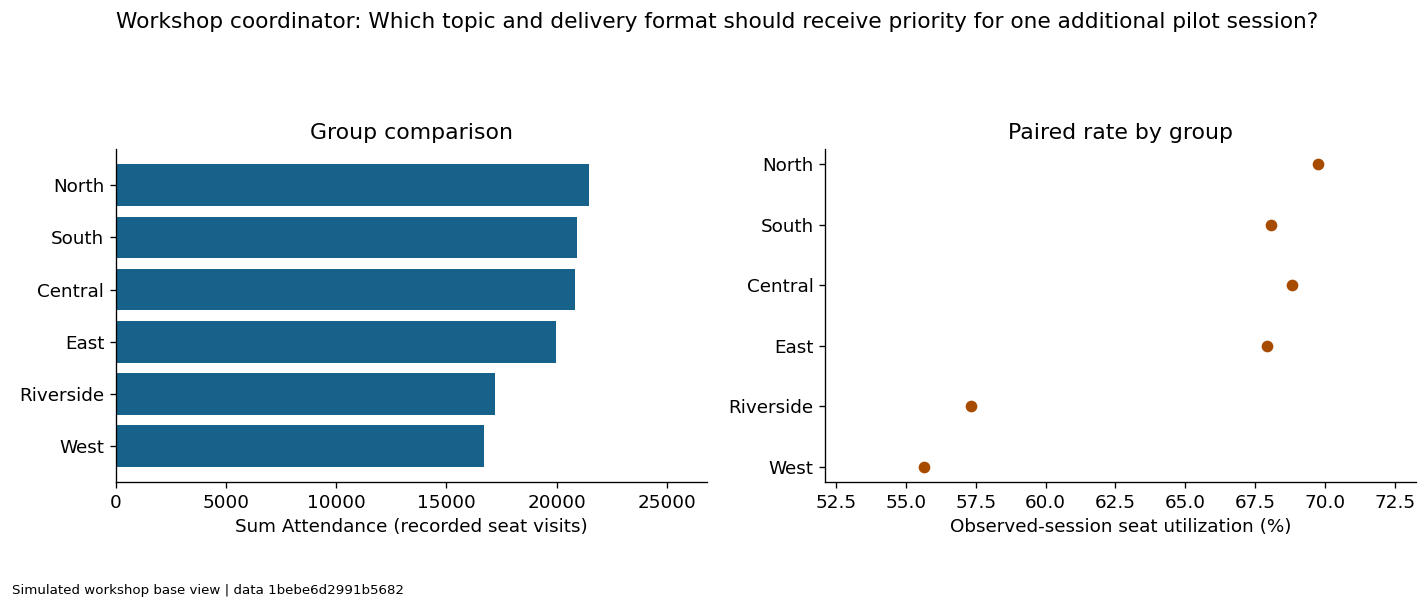

Report version saved: m05_integer_23/all_students_workshop/base_groups.png


In [8]:
fig = draw_base_view('groups',course_base_work,COURSE_BASE_VALUE_LABEL,COURSE_BASE_RATE_LABEL,
                     x_label='Capacity (seats)',period_label='Fictional month',groups=['East','North'] if 'groups'=='time' else None)
course_base_paths['groups'] = save_report(fig,COURSE_DIR/'base_groups.png',
                        WORKSHOP_AUDIENCE,WORKSHOP_QUESTION,'Simulated workshop base view',course_fingerprint)


Compare recorded volume with utilization. A large total and a high rate can describe different groups.


### Base view 2: Distribution


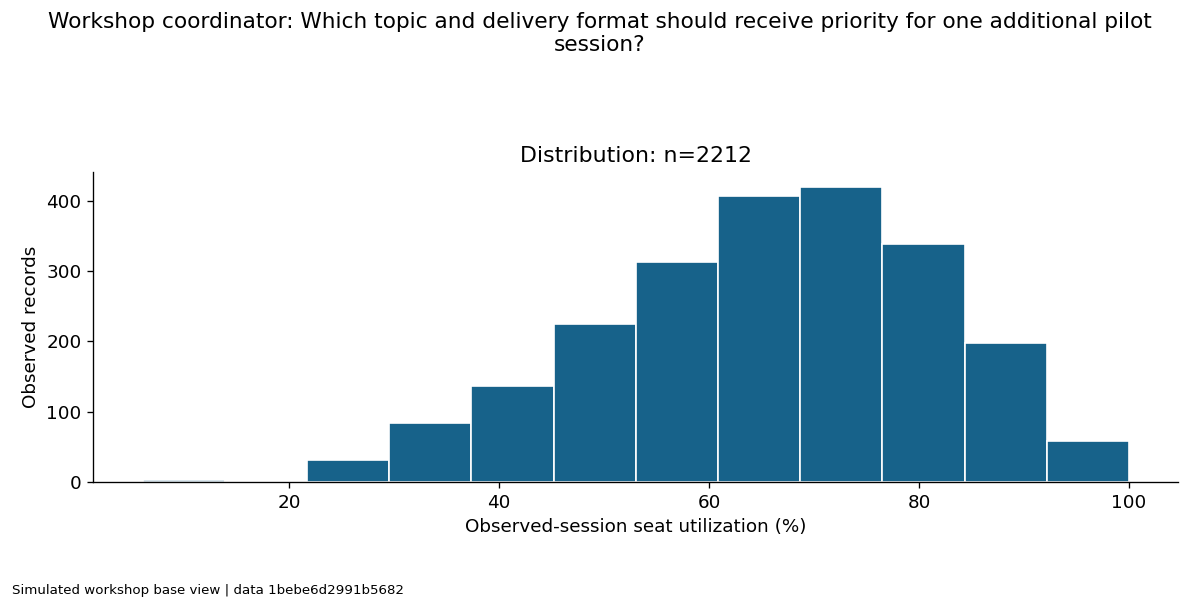

Report version saved: m05_integer_23/all_students_workshop/base_distribution.png


In [9]:
fig = draw_base_view('distribution',course_base_work,COURSE_BASE_VALUE_LABEL,COURSE_BASE_RATE_LABEL,
                     x_label='Capacity (seats)',period_label='Fictional month',groups=['East','North'] if 'distribution'=='time' else None)
course_base_paths['distribution'] = save_report(fig,COURSE_DIR/'base_distribution.png',
                        WORKSHOP_AUDIENCE,WORKSHOP_QUESTION,'Simulated workshop base view',course_fingerprint)


Inspect the distribution of session-level utilization. Explain what one record represents.


### Base view 3: Relationship


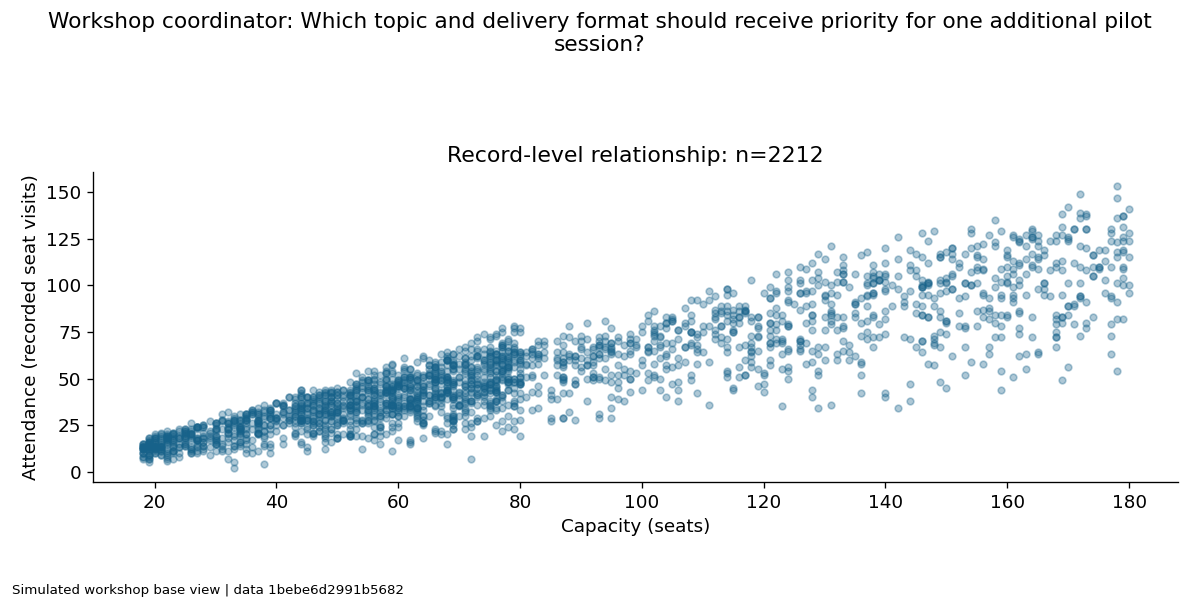

Report version saved: m05_integer_23/all_students_workshop/base_relationship.png


In [10]:
fig = draw_base_view('relationship',course_base_work,COURSE_BASE_VALUE_LABEL,COURSE_BASE_RATE_LABEL,
                     x_label='Capacity (seats)',period_label='Fictional month',groups=['East','North'] if 'relationship'=='time' else None)
course_base_paths['relationship'] = save_report(fig,COURSE_DIR/'base_relationship.png',
                        WORKSHOP_AUDIENCE,WORKSHOP_QUESTION,'Simulated workshop base view',course_fingerprint)


Inspect capacity and attendance together. Their association does not establish causation.


### Base view 4: Time comparison


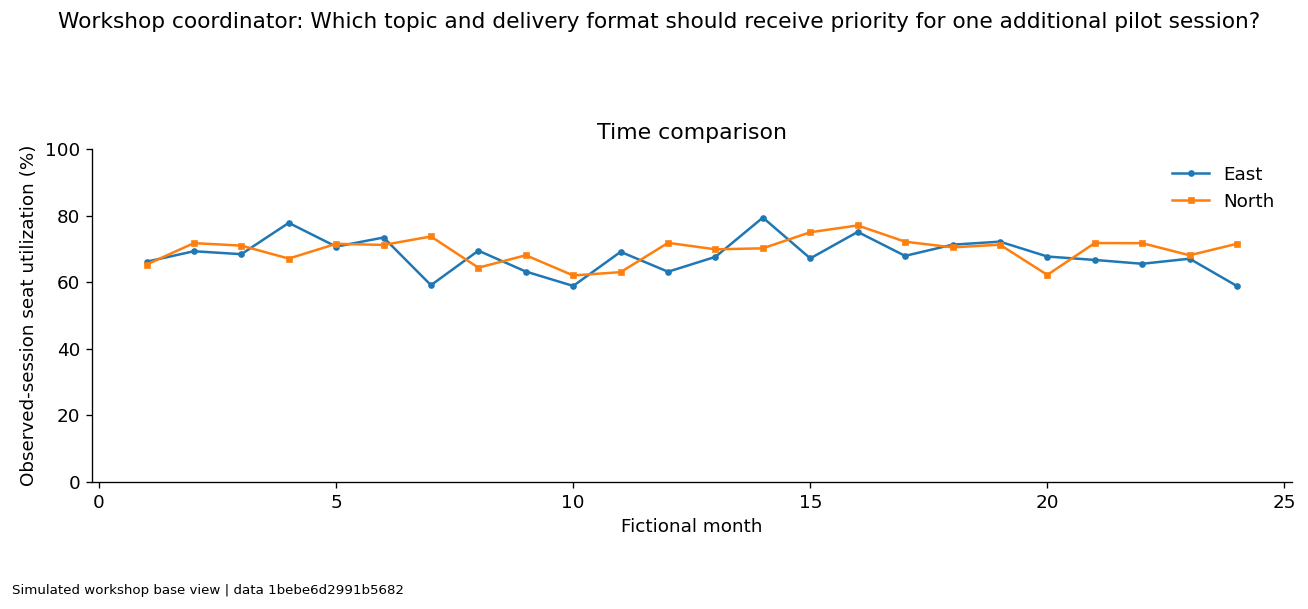

Report version saved: m05_integer_23/all_students_workshop/base_time.png


In [11]:
fig = draw_base_view('time',course_base_work,COURSE_BASE_VALUE_LABEL,COURSE_BASE_RATE_LABEL,
                     x_label='Capacity (seats)',period_label='Fictional month',groups=['East','North'] if 'time'=='time' else None)
course_base_paths['time'] = save_report(fig,COURSE_DIR/'base_time.png',
                        WORKSHOP_AUDIENCE,WORKSHOP_QUESTION,'Simulated workshop base view',course_fingerprint)


Compare the two service areas over the fictional monthly periods and consider reporting coverage.


### Base view 5: Small multiples


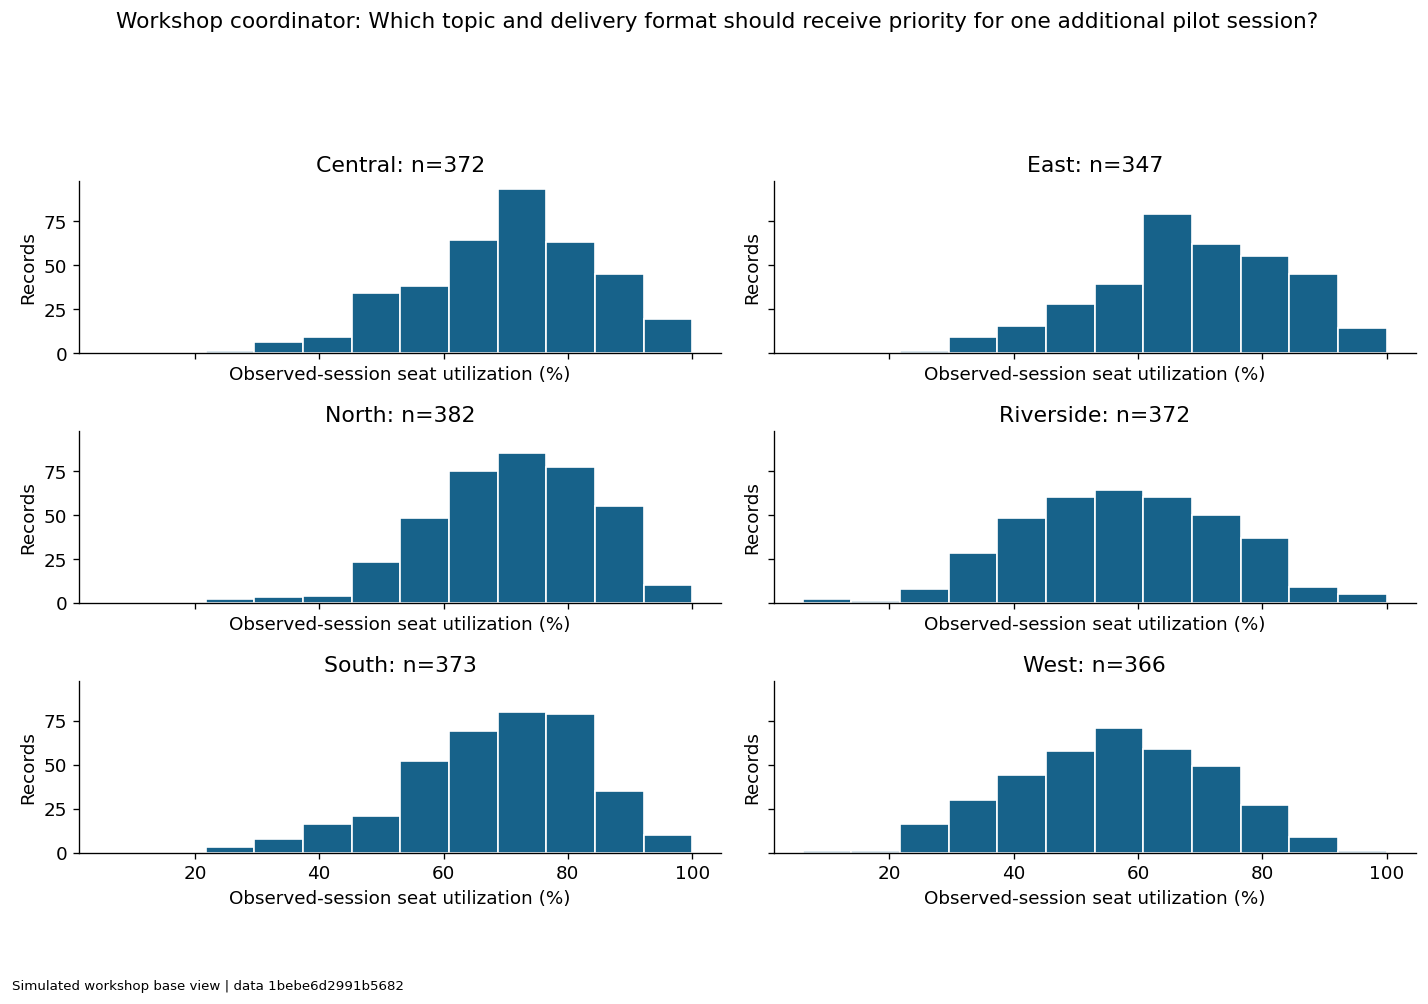

Report version saved: m05_integer_23/all_students_workshop/base_small_multiples.png


In [12]:
fig = draw_base_view('small_multiples',course_base_work,COURSE_BASE_VALUE_LABEL,COURSE_BASE_RATE_LABEL,
                     x_label='Capacity (seats)',period_label='Fictional month',groups=['East','North'] if 'small_multiples'=='time' else None)
course_base_paths['small_multiples'] = save_report(fig,COURSE_DIR/'base_small_multiples.png',
                        WORKSHOP_AUDIENCE,WORKSHOP_QUESTION,'Simulated workshop base view',course_fingerprint)


Compare distributions across service areas using common bins and scales.


### 5. Choose two base views to improve
Choose two different names from `groups`, `distribution`, `relationship`, `time`, and `small_multiples`. The next two code cells recreate your selected views. Change the marked visual settings and, where useful, the grouping or scope to improve their contribution to the decision. Explain how the feedback or resource guided each change in the Markdown directly below its visualization.

The default settings demonstrate how the cells run. Your source-based explanation must justify your own purposeful choices.


In [13]:
# EDIT HERE: select two different base forms.
SELECTED_VIEW_1 = 'groups'
SELECTED_VIEW_2 = 'time'
if SELECTED_VIEW_1 not in BASE_VIEWS or SELECTED_VIEW_2 not in BASE_VIEWS or SELECTED_VIEW_1==SELECTED_VIEW_2:
    raise ValueError(f'Choose two different base views from {BASE_VIEWS}.')
# EDIT HERE: use one consistent delivery scope unless you explain an intentional difference.
DELIVERY_FILTER = 'All'  # 'All', 'In person', or 'Online'.
if DELIVERY_FILTER not in {'All','In person','Online'}:raise ValueError('Choose a listed delivery format.')
course_scope = course_data.copy() if DELIVERY_FILTER=='All' else course_data.loc[course_data['delivery_format'].eq(DELIVERY_FILTER)].copy()


### Improved visualization 1: your selected base view


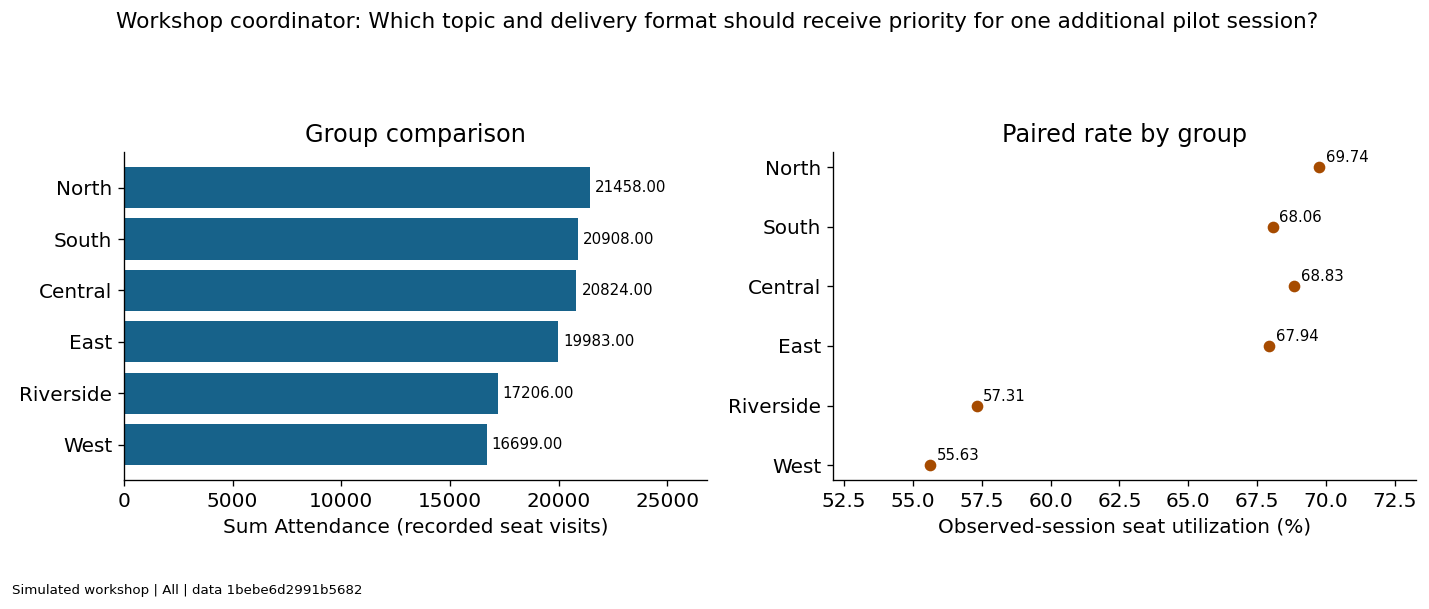

Report version saved: m05_integer_23/all_students_workshop/improved_1_groups.png


In [14]:
# EDIT HERE: adapt these display and grouping choices using your feedback or resource.
VIEW_1_GROUP_COLUMN = 'neighborhood'
VIEW_1_COLOR = '#17628a'
VIEW_1_BINS = 10
VIEW_1_FONT_SIZE = 12
VIEW_1_DIRECT_LABELS = True
VIEW_1_COMPARE_GROUPS = []  # Actual names for a time view, or [] for the first two.
course_selected_1 = make_work(course_scope,VIEW_1_GROUP_COLUMN,'attendance_visits','capacity_seats','month','capacity_seats')
fig = draw_base_view(SELECTED_VIEW_1,course_selected_1,COURSE_BASE_VALUE_LABEL,COURSE_BASE_RATE_LABEL,
                     color=VIEW_1_COLOR,bins=VIEW_1_BINS,labels=VIEW_1_DIRECT_LABELS,
                     font_size=VIEW_1_FONT_SIZE,x_label='Capacity (seats)',period_label='Fictional month',groups=VIEW_1_COMPARE_GROUPS)
course_revised_1_path = save_report(fig,COURSE_DIR/f'improved_1_{SELECTED_VIEW_1}.png',
                    WORKSHOP_AUDIENCE,WORKSHOP_QUESTION,f'Simulated workshop | {DELIVERY_FILTER}',course_fingerprint)
course_refs_1,course_counts_1 = view_references(course_selected_1,SELECTED_VIEW_1,'view1',groups=VIEW_1_COMPARE_GROUPS)


### Explain the improvement: improved visualization 1
Edit this Markdown cell beneath your visualization.

- **Base view selected:**
- **Source or feedback used:** identify the instructor comment, course resource, or external source. Include the page or section where applicable.
- **Specific guidance and modification:** explain how the guidance led to the change you made.
- **Benefit:** explain how the change improves accuracy, readability, accessibility, or interpretation for your audience.
- **Earlier and revised versions:** identify the saved images or Tableau sheets.

Cite resources in APA 7 and include them on your reference slide. Label an outside source **External**.


### Improved visualization 2: your selected base view


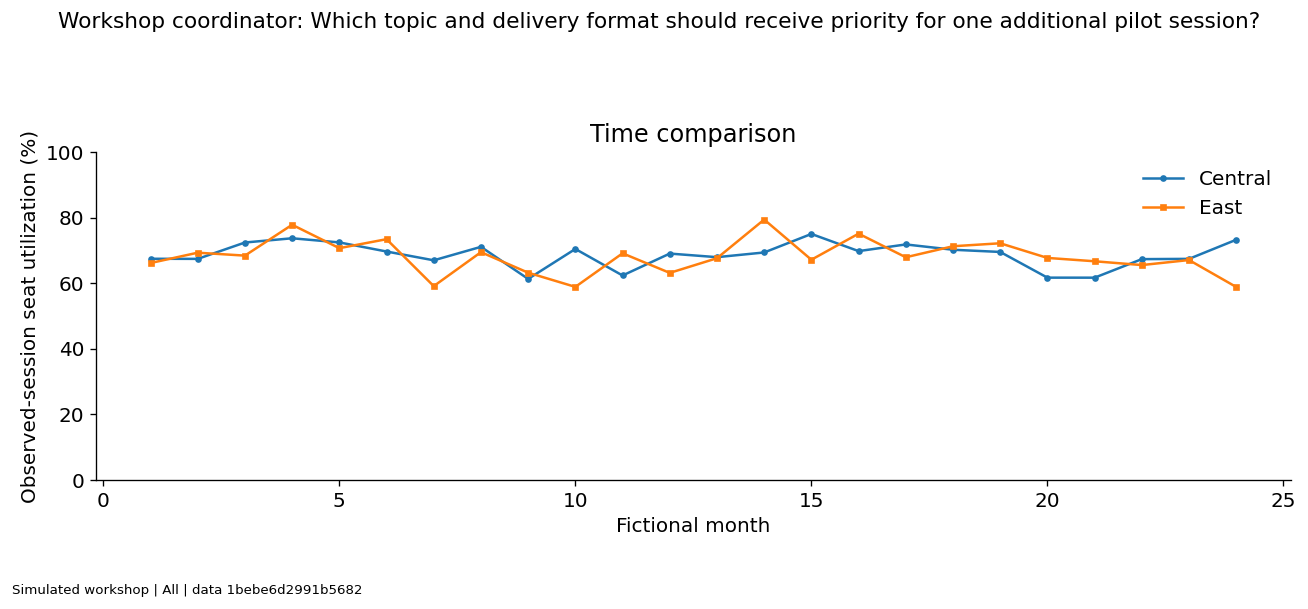

Report version saved: m05_integer_23/all_students_workshop/improved_2_time.png


In [15]:
# EDIT HERE: adapt these display and grouping choices using your feedback or resource.
VIEW_2_GROUP_COLUMN = 'neighborhood'
VIEW_2_COLOR = '#17628a'
VIEW_2_BINS = 10
VIEW_2_FONT_SIZE = 12
VIEW_2_DIRECT_LABELS = True
VIEW_2_COMPARE_GROUPS = []  # Actual names for a time view, or [] for the first two.
course_selected_2 = make_work(course_scope,VIEW_2_GROUP_COLUMN,'attendance_visits','capacity_seats','month','capacity_seats')
fig = draw_base_view(SELECTED_VIEW_2,course_selected_2,COURSE_BASE_VALUE_LABEL,COURSE_BASE_RATE_LABEL,
                     color=VIEW_2_COLOR,bins=VIEW_2_BINS,labels=VIEW_2_DIRECT_LABELS,
                     font_size=VIEW_2_FONT_SIZE,x_label='Capacity (seats)',period_label='Fictional month',groups=VIEW_2_COMPARE_GROUPS)
course_revised_2_path = save_report(fig,COURSE_DIR/f'improved_2_{SELECTED_VIEW_2}.png',
                    WORKSHOP_AUDIENCE,WORKSHOP_QUESTION,f'Simulated workshop | {DELIVERY_FILTER}',course_fingerprint)
course_refs_2,course_counts_2 = view_references(course_selected_2,SELECTED_VIEW_2,'view2',groups=VIEW_2_COMPARE_GROUPS)


### Explain the improvement: improved visualization 2
Edit this Markdown cell beneath your visualization.

- **Base view selected:**
- **Source or feedback used:** identify the instructor comment, course resource, or external source. Include the page or section where applicable.
- **Specific guidance and modification:** explain how the guidance led to the change you made.
- **Benefit:** explain how the change improves accuracy, readability, accessibility, or interpretation for your audience.
- **Earlier and revised versions:** identify the saved images or Tableau sheets.

Cite resources in APA 7 and include them on your reference slide. Label an outside source **External**.


### 6. NEW visualization: cost and recorded demand
The new visualization compares **cost per recorded visit** on the horizontal axis with **waitlist requests per 100 available seats** on the vertical axis. Each point represents one topic–delivery-format option. Candidate IDs match the accompanying table.

| Additional measure | Calculation |
|---|---|
| Cost per recorded visit | Cost of sessions with known attendance ÷ attendance from those same sessions |
| Cost per recorded attendance-hour | Cost of sessions with known attendance ÷ sum of attendance × duration for those sessions |
| Waitlist requests per 100 seats | 100 × recorded waitlist requests ÷ available seats for the same scope |

Compare the visit and attendance-hour cost definitions. Use utilization and reporting coverage to qualify the choice. These are historical descriptive measures, not forecasts of the cost or attendance of another session. The original source records and generator remain unchanged.


In [16]:
# Add Module 5 summary measures without modifying the workshop source.
def module5_summary(frame, by='topic'):
    result = workshop_summary(frame, by).copy()
    observed = frame.dropna(subset=['attendance_visits']).copy()

    # Calculate attendance-hours by pairing recorded attendance directly with duration
    observed['recorded_attendance_hours'] = observed['attendance_visits'] * observed['duration_hours']
    hours = observed.groupby(by, observed=True)['recorded_attendance_hours'].sum(min_count=1)
    result = result.join(hours)

    # Metric 1: Cost per visit matches only to sessions with known attendance
    result['cost_per_recorded_visit_usd'] = result['cost_per_visit_usd']

    # Metric 2: Cost per attendance-hour ensures denominator pairs with the correct numerator
    result['cost_per_recorded_attendance_hour_usd'] = (
        result['cost_observed'] / result['recorded_attendance_hours'].replace(0, np.nan))

    # Metric 3: Waitlist pressure normalized per 100 available seats across all sessions
    result['waitlist_requests_per_100_seats'] = 100 * result['waitlist_count'] / result['capacity_all']
    result['mean_session_cost_usd'] = result['operating_cost_usd'] / result['sessions']
    return result

# Inspect all topic–format options before making your own recommendation.
course_options = module5_summary(course_data, ['topic', 'delivery_format'])
display(course_options[['sessions', 'observed_sessions', 'coverage_pct', 'utilization_pct',
                        'waitlist_requests_per_100_seats', 'cost_per_recorded_visit_usd',
                        'cost_per_recorded_attendance_hour_usd']].round(2))
course_options.to_csv(COURSE_DIR / 'topic_format_decision_measures.csv')


def draw_cost_demand(frame,cost_basis='visit',labels=True,marker_size=65,label_size=9):
    if cost_basis not in {'visit','attendance_hour'}:raise ValueError('Choose visit or attendance_hour.')
    candidates=module5_summary(frame,['topic','delivery_format']).reset_index()
    candidates['candidate_id']=[f'C{i+1:02d}' for i in range(len(candidates))]
    field='cost_per_recorded_visit_usd' if cost_basis=='visit' else 'cost_per_recorded_attendance_hour_usd'
    fig,ax=plt.subplots(figsize=(11,6))
    colors={'In person':'#17628a','Online':'#a64b00'}
    for delivery,g in candidates.groupby('delivery_format',observed=True):
        ax.scatter(g[field],g['waitlist_requests_per_100_seats'],s=marker_size,label=delivery,color=colors[delivery])
    if labels:
        for _,r in candidates.iterrows():
            if np.isfinite(r[field]) and np.isfinite(r['waitlist_requests_per_100_seats']):
                ax.annotate(r['candidate_id'],(r[field],r['waitlist_requests_per_100_seats']),xytext=(5,5),textcoords='offset points',fontsize=label_size)
    ax.set(xlabel='USD per recorded visit' if cost_basis=='visit' else 'USD per recorded attendance-hour',
           ylabel='Waitlist requests per 100 seats',title='NEW: cost and recorded demand')
    ax.margins(x=.2,y=.2);ax.set_xlim(left=0);ax.set_ylim(bottom=0);ax.legend()
    refs={}
    for _,r in candidates.iterrows():
        rows=frame.loc[frame['topic'].eq(r['topic']) & frame['delivery_format'].eq(r['delivery_format'])]
        observed=rows.dropna(subset=['attendance_visits'])
        numerator=math.fsum(float(v) for v in observed['operating_cost_usd'])
        denominator=(math.fsum(float(v) for v in observed['attendance_visits']) if cost_basis=='visit' else
                     math.fsum(float(a*d) for a,d in zip(observed['attendance_visits'],observed['duration_hours'])))
        refs[f'new:cost:{r["candidate_id"]}']=numerator/denominator if denominator else np.nan
        refs[f'new:pressure:{r["candidate_id"]}']=100*math.fsum(float(v) for v in rows['waitlist_count'])/math.fsum(float(v) for v in rows['capacity_seats'])
    return fig,candidates,refs

sessions  observed_sessions  coverage_pct  \
topic             delivery_format                                              
Career skills     In person             280                270         96.43   
                  Online                299                282         94.31   
Creative practice In person             275                261         94.91   
                  Online                292                284         97.26   
Digital skills    In person             284                275         96.83   
                  Online                298                293         98.32   
Personal finance  In person             273                266         97.44   
                  Online                286                281         98.25   

                                   utilization_pct  \
topic             delivery_format                    
Career skills     In person                  67.89   
                  Online                     62.46   
Creative practice In person                  67.81   
                  Online                     63.21   
Digital skills    In person                  68.41   
                  Online                     62.72   
Personal finance  In person                  67.94   
                  Online                     64.44   

                                   waitlist_requests_per_100_seats  \
topic             delivery_format                                    
Career skills     In person                                   1.47   
                  Online                                      3.42   
Creative practice In person                                   2.13   
                  Online                                      2.92   
Digital skills    In person                                   2.15   
                  Online                                      3.92   
Personal finance  In person                                   2.65   
                  Online                                      3.44   

                                   cost_per_recorded_visit_usd  \
topic             delivery_format                                
Career skills     In person                               8.44   
                  Online                                  3.73   
Creative practice In person                               8.91   
                  Online                                  3.84   
Digital skills    In person                               7.32   
                  Online                                  3.58   
Personal finance  In person                               8.80   
                  Online                                  4.12   

                                   cost_per_recorded_attendance_hour_usd  
topic             delivery_format                                         
Career skills     In person                                         4.13  
                  Online                                            1.86  
Creative practice In person                                         4.42  
                  Online                                            2.03  
Digital skills    In person                                         3.75  
                  Online                                            1.77  
Personal finance  In person                                         4.59  
                  Online                                            2.00

### New visualization: first draft


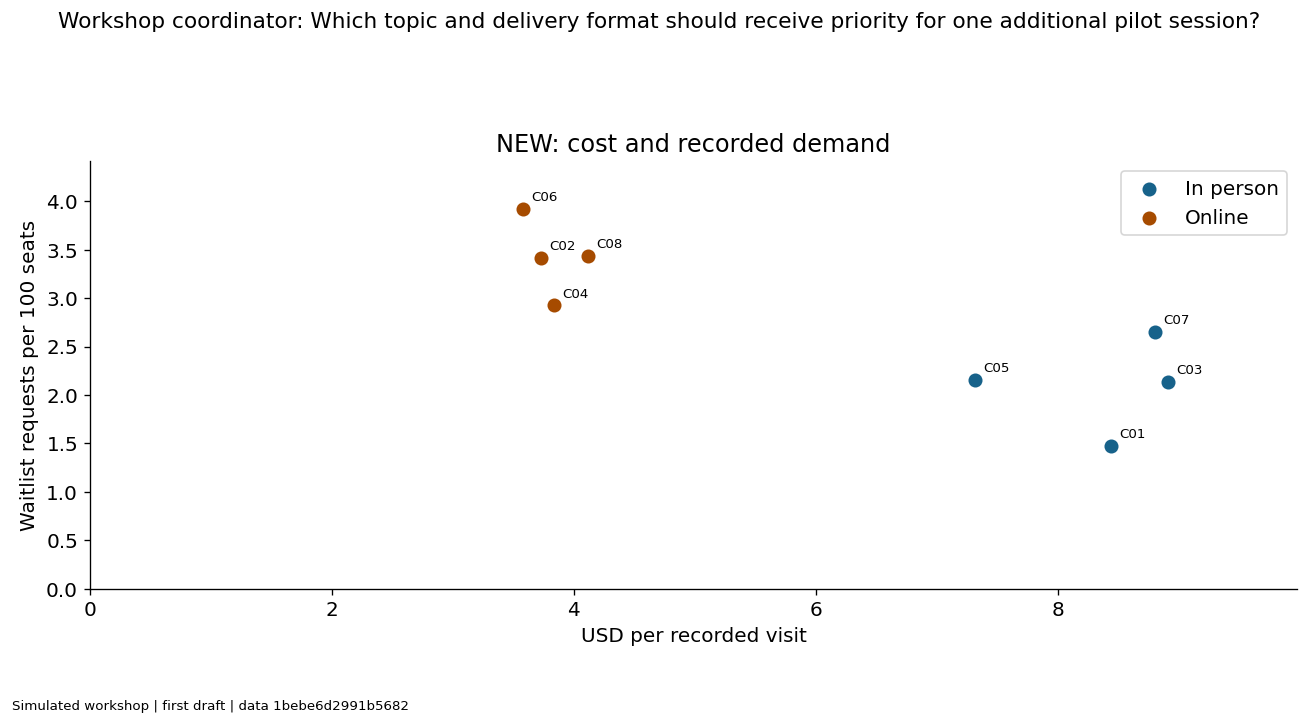

Report version saved: m05_integer_23/all_students_workshop/new_cost_demand_draft.png


,candidate_id,topic,delivery_format,utilization_pct,coverage_pct,cost_per_recorded_visit_usd,cost_per_recorded_attendance_hour_usd,waitlist_requests_per_100_seats
0,C01,Career skills,In person,67.89,96.43,8.44,4.13,1.47
1,C02,Career skills,Online,62.46,94.31,3.73,1.86,3.42
2,C03,Creative practice,In person,67.81,94.91,8.91,4.42,2.13
3,C04,Creative practice,Online,63.21,97.26,3.84,2.03,2.92
4,C05,Digital skills,In person,68.41,96.83,7.32,3.75,2.15
5,C06,Digital skills,Online,62.72,98.32,3.58,1.77,3.92
6,C07,Personal finance,In person,67.94,97.44,8.80,4.59,2.65
7,C08,Personal finance,Online,64.44,98.25,4.12,2.00,3.44


In [17]:
fig,course_draft_candidates,_ = draw_cost_demand(course_scope,'visit',labels=True,marker_size=55,label_size=8)
course_new_draft_path = save_report(fig,COURSE_DIR/'new_cost_demand_draft.png',WORKSHOP_AUDIENCE,
                                   WORKSHOP_QUESTION,'Simulated workshop | first draft',course_fingerprint)
display(course_draft_candidates[['candidate_id','topic','delivery_format','utilization_pct','coverage_pct',
                                'cost_per_recorded_visit_usd','cost_per_recorded_attendance_hour_usd',
                                'waitlist_requests_per_100_seats']].round(2))


Inspect the first draft and choose a source-informed improvement for its readability, accessibility, accuracy, or interpretation. The following cell builds the revised version.


### New visualization: revised version


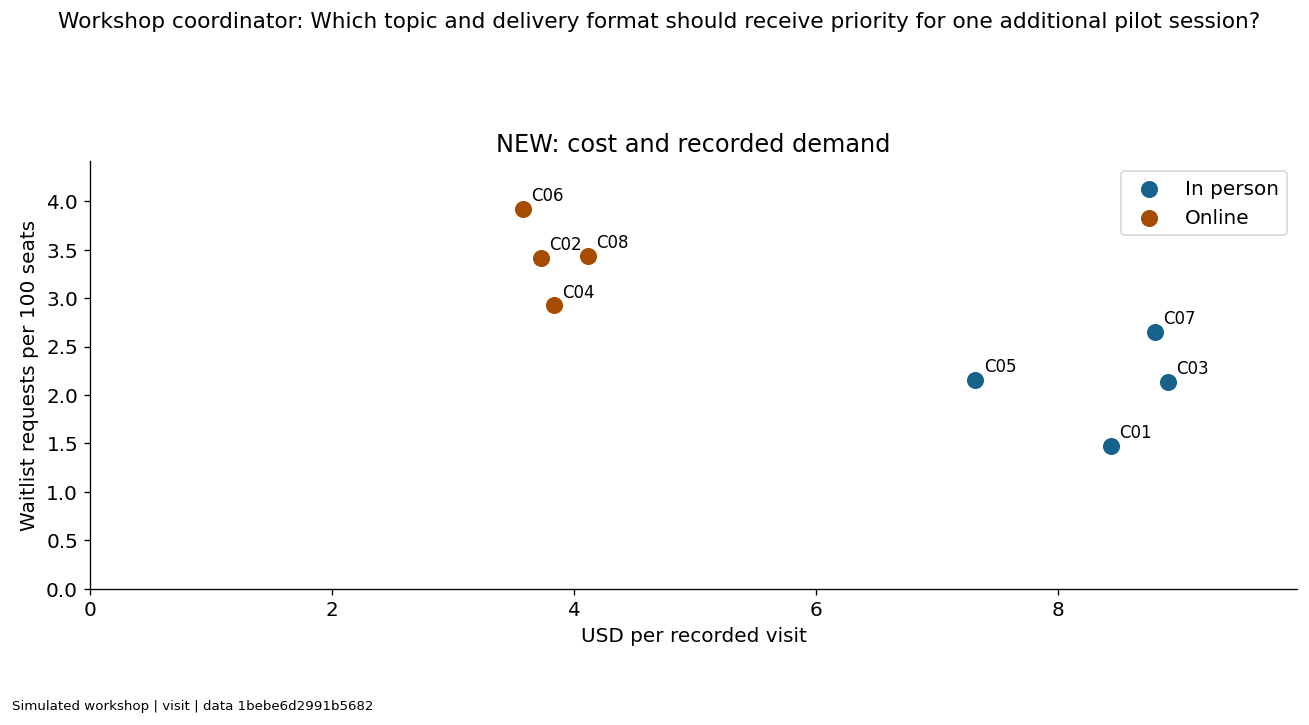

Report version saved: m05_integer_23/all_students_workshop/new_cost_demand_revised.png


,candidate_id,topic,delivery_format,utilization_pct,coverage_pct,cost_per_recorded_visit_usd,cost_per_recorded_attendance_hour_usd,waitlist_requests_per_100_seats
0,C01,Career skills,In person,67.89,96.43,8.44,4.13,1.47
1,C02,Career skills,Online,62.46,94.31,3.73,1.86,3.42
2,C03,Creative practice,In person,67.81,94.91,8.91,4.42,2.13
3,C04,Creative practice,Online,63.21,97.26,3.84,2.03,2.92
4,C05,Digital skills,In person,68.41,96.83,7.32,3.75,2.15
5,C06,Digital skills,Online,62.72,98.32,3.58,1.77,3.92
6,C07,Personal finance,In person,67.94,97.44,8.80,4.59,2.65
7,C08,Personal finance,Online,64.44,98.25,4.12,2.00,3.44


In [18]:
# EDIT HERE: revise the new visualization and justify your choices in Markdown below.
WORKSHOP_COST_BASIS = 'visit'  # Also examine 'attendance_hour' as the analytical alternative.
COST_SHOW_LABELS = True
COST_MARKER_SIZE = 85
COST_LABEL_SIZE = 10
fig,course_candidates,course_new_refs = draw_cost_demand(course_scope,WORKSHOP_COST_BASIS,
        COST_SHOW_LABELS,COST_MARKER_SIZE,COST_LABEL_SIZE)
course_new_path = save_report(fig,COURSE_DIR/'new_cost_demand_revised.png',WORKSHOP_AUDIENCE,
                             WORKSHOP_QUESTION,f'Simulated workshop | {WORKSHOP_COST_BASIS}',course_fingerprint)
display(course_candidates[['candidate_id','topic','delivery_format','utilization_pct','coverage_pct',
                          'cost_per_recorded_visit_usd','cost_per_recorded_attendance_hour_usd',
                          'waitlist_requests_per_100_seats']].round(2))
course_candidates.to_csv(COURSE_DIR/'new_cost_demand_checks.csv',index=False)


### Explain the improvement: new cost–demand visualization
Edit this Markdown cell beneath your visualization.

- **First draft and added measure:**
- **Source or feedback used:** identify the instructor comment, course resource, or external source. Include the page or section where applicable.
- **Specific guidance and modification:** explain how the guidance led to the change you made.
- **Benefit:** explain how the change improves accuracy, readability, accessibility, or interpretation for your audience.
- **Earlier and revised versions:** identify the saved images or Tableau sheets.

Cite resources in APA 7 and include them on your reference slide. Label an outside source **External**.


### 7. Compare the cost definitions and a plausible alternative
Compare the topic–format options using demand, utilization, cost, and reporting coverage. Examine whether ranking the same options by cost per visit versus cost per attendance-hour changes the recommendation. Explain which definition fits the decision; similar results can support a stable recommendation.


In [19]:
course_cost_comparison=course_options[['utilization_pct','waitlist_requests_per_100_seats',
    'cost_per_recorded_visit_usd','cost_per_recorded_attendance_hour_usd','coverage_pct']].copy()
course_cost_comparison['visit_cost_rank']=course_cost_comparison['cost_per_recorded_visit_usd'].rank(method='min')
course_cost_comparison['attendance_hour_cost_rank']=course_cost_comparison['cost_per_recorded_attendance_hour_usd'].rank(method='min')
display(course_cost_comparison.round(2))
course_cost_comparison.to_csv(COURSE_DIR/'cost_basis_comparison.csv')


utilization_pct  \
topic             delivery_format                    
Career skills     In person                  67.89   
                  Online                     62.46   
Creative practice In person                  67.81   
                  Online                     63.21   
Digital skills    In person                  68.41   
                  Online                     62.72   
Personal finance  In person                  67.94   
                  Online                     64.44   

                                   waitlist_requests_per_100_seats  \
topic             delivery_format                                    
Career skills     In person                                   1.47   
                  Online                                      3.42   
Creative practice In person                                   2.13   
                  Online                                      2.92   
Digital skills    In person                                   2.15   
                  Online                                      3.92   
Personal finance  In person                                   2.65   
                  Online                                      3.44   

                                   cost_per_recorded_visit_usd  \
topic             delivery_format                                
Career skills     In person                               8.44   
                  Online                                  3.73   
Creative practice In person                               8.91   
                  Online                                  3.84   
Digital skills    In person                               7.32   
                  Online                                  3.58   
Personal finance  In person                               8.80   
                  Online                                  4.12   

                                   cost_per_recorded_attendance_hour_usd  \
topic             delivery_format                                          
Career skills     In person                                         4.13   
                  Online                                            1.86   
Creative practice In person                                         4.42   
                  Online                                            2.03   
Digital skills    In person                                         3.75   
                  Online                                            1.77   
Personal finance  In person                                         4.59   
                  Online                                            2.00   

                                   coverage_pct  visit_cost_rank  \
topic             delivery_format                                  
Career skills     In person               96.43              6.0   
                  Online                  94.31              2.0   
Creative practice In person               94.91              8.0   
                  Online                  97.26              3.0   
Digital skills    In person               96.83              5.0   
                  Online                  98.32              1.0   
Personal finance  In person               97.44              7.0   
                  Online                  98.25              4.0   

                                   attendance_hour_cost_rank  
topic             delivery_format                             
Career skills     In person                              6.0  
                  Online                                 2.0  
Creative practice In person                              7.0  
                  Online                                 4.0  
Digital skills    In person                              5.0  
                  Online                                 1.0  
Personal finance  In person                              8.0  
                  Online                                 3.0

**Interpret the decision in this Markdown cell.** State the preferred topic–format option, a plausible alternative, the tradeoff supported by the three views, whether the cost definition changes the recommendation, and a limitation. Explain how the evidence from your selected base views and new visualization works together.


### 8. Verify two displayed quantities from different final visualizations
The reference keys below correspond to the actual selected views and the new visualization. Enter two values you display, using different view prefixes (`view1`, `view2`, or `new`). Retain the verification table. A blank dictionary reports that verification is unfinished.


In [20]:
def check_displayed_values(displayed, references, count_keys, destination, view_for_key=None):
    """Checks student-entered chart values against source references using strict tolerances."""
    if not displayed:
        pd.DataFrame(columns=['displayed', 'source_reference', 'difference', 'tolerance']).to_csv(destination)
        print('NOT YET VERIFIED: enter two values actually displayed in your charts.')
        return pd.DataFrame()
    if len(displayed) < 2 or not set(displayed).issubset(references):
        raise ValueError('Enter at least two displayed values with matching reference keys.')
    if view_for_key is not None and len({view_for_key[key] for key in displayed}) < 2:
        raise ValueError('Choose two displayed quantities from different views in the coordinated report.')

    # Compare entries to baseline; integer keys use zero tolerance, floats use 0.0051
    result = pd.DataFrame({'displayed': pd.Series(displayed, dtype=float)})
    result['source_reference'] = pd.Series(references)
    result['difference'] = result['displayed'] - result['source_reference']
    result['tolerance'] = [0.0 if key in count_keys else .0051 for key in result.index]
    display(result)

    if not np.isfinite(result.to_numpy()).all() or not result['difference'].abs().le(result['tolerance']).all():
        raise ValueError('Resolve the filter, units, missingness, aggregation, or rounding difference.')
    result.to_csv(destination)
    print('Entered values agree with the source-derived checks. Explain what they mean for your audience.')
    return result

# Map references to their corresponding parent views to enforce cross-view verification
course_references={**course_refs_1,**course_refs_2,**course_new_refs}
course_count_keys=course_counts_1|course_counts_2
course_reference_views={key:key.split(':',1)[0] for key in course_references}
display(pd.Series(course_references,name='Source-derived value').rename_axis('Reference key').to_frame())

# EDIT HERE: Populate dictionary with two displayed values mapping to keys from the list above
WORKSHOP_DISPLAYED_VALUES = {}
course_checks=check_displayed_values(WORKSHOP_DISPLAYED_VALUES,course_references,course_count_keys,
    COURSE_DIR/'actual_claim_checks.csv',view_for_key=course_reference_views)
pd.Series(course_references,name='source_value').to_csv(COURSE_DIR/'reference_values.csv')

,Source-derived value
Reference key,
view1:group:Central,20824.000000
view1:rate:Central,68.832843
view1:group:East,19983.000000
view1:rate:East,67.943967
view1:group:North,21458.000000
...,...
new:pressure:C06,3.920975
new:cost:C07,8.803649
new:pressure:C07,2.652635


NOT YET VERIFIED: enter two values actually displayed in your charts.


### Save your workshop work
Save this notebook with its chart outputs and Markdown explanations. The optional ZIP retains the generated source, chart versions, and calculation checks. Tableau students save the workbook, source data, revised sheets, and equivalent checks.

DSC 363/BUS 363 students normally present the two improved selections and the new visualization from this section. DSC 563 students continue below. Undergraduates choosing the separate-data bonus also continue below.


In [21]:
DOWNLOAD_WORKSHOP_EVIDENCE = False # update to `True` if you want the download
workshop_evidence=WORK_ROOT/f'm05_integer_{STUDENT_INTEGER}_workshop_evidence.zip'
with zipfile.ZipFile(workshop_evidence,'w',compression=zipfile.ZIP_DEFLATED) as archive:
    for item in sorted(COURSE_DIR.iterdir()):
        if item.is_file():archive.write(item,arcname=item.name)
download_if_requested(workshop_evidence,DOWNLOAD_WORKSHOP_EVIDENCE)


## Graduate students
  **or Undergraduates who want bonus points**

Use suitable independently selected data, including **the same unchanged source used in Module 4**. Import the source data here; no old chart files or chart code need to be transferred. The code below can generate the five base forms for your source, and you select two to improve. If you reuse data from Module 4, you can paste the code to regenerate the plots or import the those visualizations files.

Define an equivalent decision for a named audience, compare at least two plausible options using data-supported criteria, and create a new visualization using an additional field or derived measure. Cost and duration can be useful when present and relevant; choose a suitable additional measure for your source. DSC 563 presents this section and retains the workshop work as practice. The separate-data option follows the existing undergraduate bonus policy.


### State your external-data decision in Markdown
Identify your audience, the decision, at least two plausible options, and the criteria supported by your source. Identify the additional field or derived measure that your new visualization will introduce.


### 9. Import your external source
Save the unchanged CSV in Drive and share it with the instructor. In Colab, use the file chooser; outside Colab, supply its path below. Enter a source citation and the audience/question used in chart titles. The student integer labels your work and never changes the external observations.


In [22]:
# EDIT HERE: document the independently selected source and analytical purpose.
EXTERNAL_SOURCE_CITATION = ''  # Publisher, dataset title, source URL, and release/download date.
EXTERNAL_AUDIENCE = ''
EXTERNAL_QUESTION = ''  # State a decision the named audience can make.
EXTERNAL_CSV_SEPARATOR = ','
EXTERNAL_CSV_ENCODING = 'utf-8'
EXTERNAL_LOCAL_CSV_PATH = ''  # Outside Colab only; Colab opens a file chooser.

if COMPLETE_EXTERNAL_PHASE:
    if not all(text.strip() for text in [EXTERNAL_SOURCE_CITATION, EXTERNAL_AUDIENCE, EXTERNAL_QUESTION]):
        raise ValueError('Complete the source citation, audience, and question before importing.')
    try:
        from google.colab import files
    except ImportError:
        if not EXTERNAL_LOCAL_CSV_PATH:
            raise ValueError('Outside Colab, enter EXTERNAL_LOCAL_CSV_PATH for your unchanged CSV.')
        external_source_name = Path(EXTERNAL_LOCAL_CSV_PATH).name
        external_source_bytes = Path(EXTERNAL_LOCAL_CSV_PATH).read_bytes()
    else:
        uploaded = files.upload()
        if len(uploaded) != 1:
            raise ValueError('Choose exactly one CSV, then rerun this import cell.')
        external_source_name, external_source_bytes = next(iter(uploaded.items()))
    external_data = pd.read_csv(io.BytesIO(external_source_bytes),
                                sep=EXTERNAL_CSV_SEPARATOR, encoding=EXTERNAL_CSV_ENCODING)
    if external_data.empty or not external_data.columns.is_unique:
        raise ValueError('Use a nonempty source with distinct column names.')
    external_fingerprint = data_fingerprint(external_data)
    external_analysis = external_data.copy()  # Derive measures in this copy; preserve the source.
    EXTERNAL_DIR = WORK_ROOT / f'external_{external_fingerprint}'
    EXTERNAL_DIR.mkdir(parents=True, exist_ok=True)
    # Retain the uploaded bytes unchanged as well as the parsed source identity.
    (EXTERNAL_DIR / 'source_snapshot.csv').write_bytes(external_source_bytes)
    external_identity = {
        'section': 'External data', 'route': 'separate', 'student_integer': STUDENT_INTEGER,
        'notebook_release': NOTEBOOK_RELEASE, 'source': EXTERNAL_SOURCE_CITATION,
        'source_filename': external_source_name,
        'source_sha256': hashlib.sha256(external_source_bytes).hexdigest(),
        'shape': list(external_data.shape), 'fingerprint': external_fingerprint
    }
    (EXTERNAL_DIR / 'dataset_identity.json').write_text(json.dumps(external_identity, indent=2), encoding='utf-8')
    display(pd.Series(external_identity, dtype=object).to_frame('Value'))
    display(external_data.head())
    display(external_data.isna().sum().rename('Missing values').to_frame())
    print('Available columns:', list(external_data.columns))
    print('Duplicate complete rows:', int(external_data.duplicated().sum()), '(reported, not deleted)')
else:
    print('External-data work is not selected. Continue to Prepare your presentation.')


ValueError: Complete the source citation, audience, and question before importing.

### 10. Set the fields for the five base forms
Use actual column names and units. Supply a period and second numeric field when available. Without a second field, the relationship example compares group size with group mean; without a period, the time alternative compares within-group distributions. Choose the two forms that fit your question.

Add calculated fields to `external_analysis` when needed, preserving `external_data` and the original source snapshot.


In [ ]:
# EDIT HERE: map your actual fields and choose a justified aggregation.
EXTERNAL_CATEGORY_COLUMN = ''
EXTERNAL_VALUE_COLUMN = ''
EXTERNAL_VALUE_LABEL = ''
EXTERNAL_X_COLUMN = ''
EXTERNAL_X_LABEL = ''  # Include units when using a second numeric field.
EXTERNAL_PERIOD_COLUMN = ''
EXTERNAL_PERIOD_IS_DATE = False
EXTERNAL_DENOMINATOR_COLUMN = ''  # Only when a defensible rate is appropriate.
EXTERNAL_RATE_LABEL = ''
EXTERNAL_AGGREGATION = 'mean'  # 'sum', 'mean', or 'median'.
EXTERNAL_ALTERNATIVE_AGGREGATION = 'median'
if COMPLETE_EXTERNAL_PHASE:
    if not EXTERNAL_VALUE_LABEL or EXTERNAL_AGGREGATION not in {'sum','mean','median'}:
        raise ValueError('Provide a measure label with units and a justified aggregation.')
    external_work=make_work(external_analysis,EXTERNAL_CATEGORY_COLUMN,EXTERNAL_VALUE_COLUMN,
        EXTERNAL_X_COLUMN,EXTERNAL_PERIOD_COLUMN,EXTERNAL_DENOMINATOR_COLUMN,EXTERNAL_PERIOD_IS_DATE)
    external_analysis.to_csv(EXTERNAL_DIR/'prepared_data.csv',index=False)
    external_base_paths={}


### External-data base view 1: group comparison


In [ ]:
if COMPLETE_EXTERNAL_PHASE:
    fig=draw_base_view('groups',external_work,EXTERNAL_VALUE_LABEL,EXTERNAL_RATE_LABEL,EXTERNAL_AGGREGATION,x_label=EXTERNAL_X_LABEL,period_label=EXTERNAL_PERIOD_COLUMN)
    external_base_paths['groups']=save_report(fig,EXTERNAL_DIR/'base_groups.png',
        EXTERNAL_AUDIENCE,EXTERNAL_QUESTION,'External-data base view',external_fingerprint)


Inspect this form for its suitability to your audience decision. The selected improvements and their Markdown explanations follow below.


### External-data base view 2: distribution


In [ ]:
if COMPLETE_EXTERNAL_PHASE:
    fig=draw_base_view('distribution',external_work,EXTERNAL_VALUE_LABEL,EXTERNAL_RATE_LABEL,EXTERNAL_AGGREGATION,x_label=EXTERNAL_X_LABEL,period_label=EXTERNAL_PERIOD_COLUMN)
    external_base_paths['distribution']=save_report(fig,EXTERNAL_DIR/'base_distribution.png',
        EXTERNAL_AUDIENCE,EXTERNAL_QUESTION,'External-data base view',external_fingerprint)


Inspect this form for its suitability to your audience decision. The selected improvements and their Markdown explanations follow below.


### External-data base view 3: relationship


In [ ]:
if COMPLETE_EXTERNAL_PHASE:
    fig=draw_base_view('relationship',external_work,EXTERNAL_VALUE_LABEL,EXTERNAL_RATE_LABEL,EXTERNAL_AGGREGATION,x_label=EXTERNAL_X_LABEL,period_label=EXTERNAL_PERIOD_COLUMN)
    external_base_paths['relationship']=save_report(fig,EXTERNAL_DIR/'base_relationship.png',
        EXTERNAL_AUDIENCE,EXTERNAL_QUESTION,'External-data base view',external_fingerprint)


Inspect this form for its suitability to your audience decision. The selected improvements and their Markdown explanations follow below.


### External-data base view 4: time comparison


In [ ]:
if COMPLETE_EXTERNAL_PHASE:
    fig=draw_base_view('time',external_work,EXTERNAL_VALUE_LABEL,EXTERNAL_RATE_LABEL,EXTERNAL_AGGREGATION,x_label=EXTERNAL_X_LABEL,period_label=EXTERNAL_PERIOD_COLUMN)
    external_base_paths['time']=save_report(fig,EXTERNAL_DIR/'base_time.png',
        EXTERNAL_AUDIENCE,EXTERNAL_QUESTION,'External-data base view',external_fingerprint)


Inspect this form for its suitability to your audience decision. The selected improvements and their Markdown explanations follow below.


### External-data base view 5: small multiples


In [ ]:
if COMPLETE_EXTERNAL_PHASE:
    fig=draw_base_view('small_multiples',external_work,EXTERNAL_VALUE_LABEL,EXTERNAL_RATE_LABEL,EXTERNAL_AGGREGATION,x_label=EXTERNAL_X_LABEL,period_label=EXTERNAL_PERIOD_COLUMN)
    external_base_paths['small_multiples']=save_report(fig,EXTERNAL_DIR/'base_small_multiples.png',
        EXTERNAL_AUDIENCE,EXTERNAL_QUESTION,'External-data base view',external_fingerprint)


Inspect this form for its suitability to your audience decision. The selected improvements and their Markdown explanations follow below.


### 11. Select two external-data base views to improve
Choose two different base forms. Modify the chart settings or analytical choices to serve your decision, and document the guidance and benefit directly below each visualization.


In [ ]:
EXTERNAL_SELECTED_VIEW_1 = 'groups'
EXTERNAL_SELECTED_VIEW_2 = 'distribution'
if COMPLETE_EXTERNAL_PHASE and (EXTERNAL_SELECTED_VIEW_1 not in BASE_VIEWS or EXTERNAL_SELECTED_VIEW_2 not in BASE_VIEWS or EXTERNAL_SELECTED_VIEW_1==EXTERNAL_SELECTED_VIEW_2):
    raise ValueError('Choose two different external-data base forms.')


### Improved external-data visualization 1


In [ ]:
# EDIT HERE: make source-informed improvements to this selected view.
EXTERNAL_VIEW_1_COLOR = '#17628a'
EXTERNAL_VIEW_1_BINS = 10
EXTERNAL_VIEW_1_FONT_SIZE = 12
EXTERNAL_VIEW_1_DIRECT_LABELS = True
EXTERNAL_VIEW_1_COMPARE_GROUPS = []
if COMPLETE_EXTERNAL_PHASE:
    fig=draw_base_view(EXTERNAL_SELECTED_VIEW_1,external_work,EXTERNAL_VALUE_LABEL,EXTERNAL_RATE_LABEL,
        EXTERNAL_AGGREGATION,color=EXTERNAL_VIEW_1_COLOR,bins=EXTERNAL_VIEW_1_BINS,
        labels=EXTERNAL_VIEW_1_DIRECT_LABELS,font_size=EXTERNAL_VIEW_1_FONT_SIZE,x_label=EXTERNAL_X_LABEL,period_label=EXTERNAL_PERIOD_COLUMN,groups=EXTERNAL_VIEW_1_COMPARE_GROUPS)
    external_revised_1_path=save_report(fig,EXTERNAL_DIR/'improved_1.png',
        EXTERNAL_AUDIENCE,EXTERNAL_QUESTION,'External data | improved selected view',external_fingerprint)
    external_refs_1,external_counts_1=view_references(external_work,EXTERNAL_SELECTED_VIEW_1,
        'view1',EXTERNAL_AGGREGATION,EXTERNAL_VIEW_1_COMPARE_GROUPS)


### Explain the improvement: improved external-data visualization 1
Edit this Markdown cell beneath your visualization.

- **Base view selected:**
- **Source or feedback used:** identify the instructor comment, course resource, or external source. Include the page or section where applicable.
- **Specific guidance and modification:** explain how the guidance led to the change you made.
- **Benefit:** explain how the change improves accuracy, readability, accessibility, or interpretation for your audience.
- **Earlier and revised versions:** identify the saved images or Tableau sheets.

Cite resources in APA 7 and include them on your reference slide. Label an outside source **External**.


### Improved external-data visualization 2


In [ ]:
# EDIT HERE: make source-informed improvements to this selected view.
EXTERNAL_VIEW_2_COLOR = '#17628a'
EXTERNAL_VIEW_2_BINS = 10
EXTERNAL_VIEW_2_FONT_SIZE = 12
EXTERNAL_VIEW_2_DIRECT_LABELS = True
EXTERNAL_VIEW_2_COMPARE_GROUPS = []
if COMPLETE_EXTERNAL_PHASE:
    fig=draw_base_view(EXTERNAL_SELECTED_VIEW_2,external_work,EXTERNAL_VALUE_LABEL,EXTERNAL_RATE_LABEL,
        EXTERNAL_AGGREGATION,color=EXTERNAL_VIEW_2_COLOR,bins=EXTERNAL_VIEW_2_BINS,
        labels=EXTERNAL_VIEW_2_DIRECT_LABELS,font_size=EXTERNAL_VIEW_2_FONT_SIZE,x_label=EXTERNAL_X_LABEL,period_label=EXTERNAL_PERIOD_COLUMN,groups=EXTERNAL_VIEW_2_COMPARE_GROUPS)
    external_revised_2_path=save_report(fig,EXTERNAL_DIR/'improved_2.png',
        EXTERNAL_AUDIENCE,EXTERNAL_QUESTION,'External data | improved selected view',external_fingerprint)
    external_refs_2,external_counts_2=view_references(external_work,EXTERNAL_SELECTED_VIEW_2,
        'view2',EXTERNAL_AGGREGATION,EXTERNAL_VIEW_2_COMPARE_GROUPS)


### Explain the improvement: improved external-data visualization 2
Edit this Markdown cell beneath your visualization.

- **Base view selected:**
- **Source or feedback used:** identify the instructor comment, course resource, or external source. Include the page or section where applicable.
- **Specific guidance and modification:** explain how the guidance led to the change you made.
- **Benefit:** explain how the change improves accuracy, readability, accessibility, or interpretation for your audience.
- **Earlier and revised versions:** identify the saved images or Tableau sheets.

Cite resources in APA 7 and include them on your reference slide. Label an outside source **External**.


### 12. NEW external-data visualization
Use an additional field or derived measure to add evidence for your decision. The runnable example is a relationship plot: choose two actual fields from `external_analysis`, with the new dimension represented on at least one axis. You may adapt the plotting code for a more suitable form.

Explain the new measure, its units, calculation if derived, and role in the decision in the Markdown below the visualization. Use the first draft and revised cells to demonstrate a purposeful improvement.


In [ ]:
# EDIT HERE: set actual fields for the new visualization.
EXTERNAL_NEW_X_COLUMN = ''
EXTERNAL_NEW_Y_COLUMN = ''
EXTERNAL_NEW_X_LABEL = ''
EXTERNAL_NEW_Y_LABEL = ''
EXTERNAL_NEW_X_IS_DATE = False
def draw_external_new(data,x_column,y_column,x_label,y_label,x_is_date=False,size=30,alpha=.5):
    if not x_column or not y_column or x_column==y_column or not {x_column,y_column}.issubset(data.columns):
        raise ValueError('Choose two distinct actual fields for the new visualization, including the additional measure.')
    if not x_label or not y_label:raise ValueError('Label both new axes with their units.')
    x=pd.to_datetime(data[x_column],errors='raise') if x_is_date else pd.to_numeric(data[x_column],errors='raise')
    y=pd.to_numeric(data[y_column],errors='raise')
    points=pd.DataFrame({'x':x,'y':y}).dropna()
    if points.empty or np.isinf(points.select_dtypes('number').to_numpy()).any():raise ValueError('Resolve missing or infinite paired values.')
    fig,ax=plt.subplots(figsize=(11,6));ax.scatter(points['x'],points['y'],s=size,alpha=alpha,color='#17628a')
    ax.set(xlabel=x_label,ylabel=y_label,title=f'NEW external-data relationship: n={len(points)}')
    if x_is_date:
        locator=mdates.AutoDateLocator(minticks=3,maxticks=6);ax.xaxis.set_major_locator(locator);ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
    return fig,points
if COMPLETE_EXTERNAL_PHASE:
    fig,external_new_points=draw_external_new(external_analysis,EXTERNAL_NEW_X_COLUMN,EXTERNAL_NEW_Y_COLUMN,
        EXTERNAL_NEW_X_LABEL,EXTERNAL_NEW_Y_LABEL,EXTERNAL_NEW_X_IS_DATE)
    external_new_draft_path=save_report(fig,EXTERNAL_DIR/'new_draft.png',EXTERNAL_AUDIENCE,
        EXTERNAL_QUESTION,'External data | new first draft',external_fingerprint)


Inspect the first draft, identify guidance from feedback or a source, and choose a purposeful improvement for the revised version.


### New external-data visualization: revised version


In [ ]:
# EDIT HERE: modify the new visualization and explain the improvement below.
EXTERNAL_NEW_POINT_SIZE = 45
EXTERNAL_NEW_ALPHA = .65
if COMPLETE_EXTERNAL_PHASE:
    fig,external_new_points=draw_external_new(external_analysis,EXTERNAL_NEW_X_COLUMN,EXTERNAL_NEW_Y_COLUMN,
        EXTERNAL_NEW_X_LABEL,EXTERNAL_NEW_Y_LABEL,EXTERNAL_NEW_X_IS_DATE,EXTERNAL_NEW_POINT_SIZE,EXTERNAL_NEW_ALPHA)
    external_new_path=save_report(fig,EXTERNAL_DIR/'new_revised.png',EXTERNAL_AUDIENCE,
        EXTERNAL_QUESTION,'External data | new revised visualization',external_fingerprint)
    external_new_points.to_csv(EXTERNAL_DIR/'new_visualization_points.csv',index=False)


### Explain the improvement: new external-data visualization
Edit this Markdown cell beneath your visualization.

- **First draft and added measure:**
- **Source or feedback used:** identify the instructor comment, course resource, or external source. Include the page or section where applicable.
- **Specific guidance and modification:** explain how the guidance led to the change you made.
- **Benefit:** explain how the change improves accuracy, readability, accessibility, or interpretation for your audience.
- **Earlier and revised versions:** identify the saved images or Tableau sheets.

Cite resources in APA 7 and include them on your reference slide. Label an outside source **External**.


### 13. Evaluate an analytical alternative
The example compares two meaningful aggregations of the same measure. Choose suitable methods and explain which fits the decision. You may instead adapt the code for another defensible comparison. Explain whether the result changes your recommendation.


In [ ]:
if COMPLETE_EXTERNAL_PHASE:
    if EXTERNAL_ALTERNATIVE_AGGREGATION not in {'sum','mean','median'} or EXTERNAL_AGGREGATION==EXTERNAL_ALTERNATIVE_AGGREGATION:
        raise ValueError('Choose a different, meaningful alternative aggregation.')
    external_comparison=pd.DataFrame({EXTERNAL_AGGREGATION:aggregate_view(external_work,method=EXTERNAL_AGGREGATION),
        EXTERNAL_ALTERNATIVE_AGGREGATION:aggregate_view(external_work,method=EXTERNAL_ALTERNATIVE_AGGREGATION)})
    external_comparison['observed_rows']=external_work.groupby('category',observed=True)['value'].count()
    display(external_comparison.round(2));external_comparison.to_csv(EXTERNAL_DIR/'analytical_alternative.csv')


**Interpret the external-data decision here.** Explain the preferred option, plausible alternative, criteria and tradeoffs, effect of the analytical alternative, and a limitation. Connect the new visualization with the two improved selections.


### 14. Verify two displayed external-data quantities
Use two different final views. The new relationship view includes a displayed paired-record count; your improved views provide source-derived summaries. If you adapt the plotting code or scope, update these calculations to match.


In [ ]:
EXTERNAL_DISPLAYED_VALUES = {}  # Enter two actual displayed quantities from different views.
if COMPLETE_EXTERNAL_PHASE:
    external_references={**external_refs_1,**external_refs_2,'new:paired_rows':float(len(external_new_points))}
    external_count_keys=external_counts_1|external_counts_2|{'new:paired_rows'}
    external_reference_views={key:key.split(':',1)[0] for key in external_references}
    display(pd.Series(external_references,name='Source-derived value').rename_axis('Reference key').to_frame())
    external_checks=check_displayed_values(EXTERNAL_DISPLAYED_VALUES,external_references,external_count_keys,
        EXTERNAL_DIR/'actual_claim_checks.csv',view_for_key=external_reference_views)
    pd.Series(external_references,name='source_value').to_csv(EXTERNAL_DIR/'reference_values.csv')


### Save the external-data work
Save this notebook with the five generated base forms, two improved selections, new visualization versions, Markdown explanations, and checks. Keep the unchanged external source in Drive and share it with the instructor.


In [ ]:
DOWNLOAD_EXTERNAL_EVIDENCE = False
if COMPLETE_EXTERNAL_PHASE:
    external_evidence=WORK_ROOT/f'm05_integer_{STUDENT_INTEGER}_external_evidence.zip'
    with zipfile.ZipFile(external_evidence,'w',compression=zipfile.ZIP_DEFLATED) as archive:
        for item in sorted(EXTERNAL_DIR.iterdir()):
            if item.is_file():archive.write(item,arcname=item.name)
    download_if_requested(external_evidence,DOWNLOAD_EXTERNAL_EVIDENCE)


# Prepare your presentation
Present your **two improved selected views and one new visualization** in one 3–4-minute continuous video showing you and readable visuals. The five base views are preparation. Arrange your three final visualizations in a clear sequence or dashboard; interactivity is optional.

Explain the audience decision, the contribution of each visualization, two verified numerical results from different views, the analytical alternative, your recommendation, and a limitation. Briefly summarize how feedback or a source informed one improvement to each visualization. Keep the full explanations in the Markdown directly below the corresponding chart.

DSC 363/BUS 363 normally presents the workshop decision. DSC 563 presents its equivalent external-data decision. Undergraduates selecting the separate-data option present that analysis. Submit one VoiceThread; the workshop practice is not a second presentation.

Apply a specific Module 5 required-resource idea and identify its page or section. DSC 563 includes at least two distinct substantive sources: a required course resource and at least one credible external source, in addition to the dataset citation. Label an outside reference **External**. Include APA 7 citations and references.

Add source/data and working-file links in a Text comment on the first slide. Share your Colab notebook with the instructor as Editor and include the unchanged external source link when applicable. Tableau students retain their workbook, source files, chart versions, and verification summaries.

The assessment remains **220 points, due Sunday of Module 5 at 11:55 p.m. Eastern Time**. The existing dataset adjustments and shared rubric apply. No peer replies, separate written report, or code walkthrough are required.

**SAVE THIS FILE for Module 6 and your final portfolio.** Save edits and outputs in Drive and retain downloaded evidence separately.

Use the [Module 5 Presentation Directions](https://learn.utica.edu/mod/page/view.php?id=3755835) for the assignment requirements.


## AI-use disclosure
State whether you used generative AI, identify the tool and its role, and explain how you checked its work. Keep detailed coding prompts and borrowed-code citations in accordance with the syllabus coding policy.


## Sources and implementation help
Use the required Module 5 resources and cite their specific pages or sections. Technical documentation supports implementation; it does not replace substantive design reasoning. Use APA7 format for sources and references.

- <a href="https://matplotlib.org/stable/users/explain/quick_start.html" target="_blank" rel="noopener noreferrer">Matplotlib quick-start guide</a>
- <a href="https://pandas.pydata.org/docs/user_guide/missing_data.html" target="_blank" rel="noopener noreferrer">pandas missing-data guide</a>
